# Detección de emociones en mensajes de estudiantes para un tutor virtual

## 1. Introducción

Las emociones influyen directamente en el aprendizaje. La teoría de control-valor de las emociones de logro [1] sostiene que estados como la frustración, el enojo o la alegría afectan la motivación, la atención y las estrategias de estudio. Del mismo modo, los estudios sobre la dinámica afectiva durante el aprendizaje complejo [2] muestran que la confusión es un estado frecuente y, hasta cierto punto, productivo: cuando se resuelve, favorece una comprensión más profunda. Cuando no se resuelve, en cambio, tiende a convertirse en frustración y, después, en desinterés o abandono de la tarea.

En la educación presencial, un docente percibe estas señales en el rostro, el tono o las preguntas de sus estudiantes y ajusta su explicación sobre la marcha. En los entornos de aprendizaje mediados por tecnología, y en particular en los tutores virtuales basados en chatbots, esa información se pierde: el sistema responde al contenido del mensaje, pero no a la forma en que el estudiante se siente. Un tutor que no distingue entre un estudiante que pregunta por curiosidad y otro que está a punto de rendirse responderá de la misma manera a ambos.

El objetivo de este proyecto es construir un clasificador supervisado que, a partir de un mensaje escrito por un estudiante, identifique su estado emocional entre cinco clases relevantes para el contexto educativo: **frustración, confusión, enojo, alegría y neutral**. Este clasificador está pensado como un componente que, en trabajos futuros, permitirá a un tutor virtual adaptar su estrategia pedagógica, por ejemplo simplificando la explicación cuando detecta frustración o confusión.

El principal reto es la escasez de datos: no existen datasets públicos y abiertos de mensajes de estudiantes en español etiquetados con estas emociones. Para abordarlo, se construye un dataset a partir de la versión en español de GoEmotions [3], cuyas 27 emociones originales se agrupan en las cinco clases de interés, y se complementa con mensajes de contexto educativo generados con un modelo de lenguaje. Como representación de los textos se usan embeddings de un modelo Sentence-BERT multilingüe preentrenado [4] (transfer learning), sobre los cuales se entrenan y comparan estadísticamente clasificadores de aprendizaje supervisado, siguiendo una metodología de validación con repeated k-fold cross-validation.

## 2. Análisis exploratorio de datos (EDA)

En esta sección se cargan los datos de GoEmotions en español, se analizan en su forma original (28 categorías) y se transforman paso a paso hasta obtener el dataset final del proyecto, con las cinco clases de interés. Cada decisión se justifica junto al código que la implementa, y al final de cada subsección se resumen las cifras clave.

### Configuración general

Antes de empezar se importan las bibliotecas y se fijan los elementos comunes a toda la notebook:

- **Semilla global (`42`)**: se usa en todo muestreo aleatorio para que los resultados sean reproducibles.
- **Orden y paleta de colores de las clases**: cada clase tiene siempre el mismo color en todos los gráficos de la notebook (EDA, matriz de confusión, t-SNE), de modo que, por ejemplo, la frustración se reconozca a simple vista. La paleta se eligió para que los cinco colores se distingan también con los tipos de daltonismo más comunes.
- **Agrupación de emociones**: el diccionario que asigna cada emoción original de GoEmotions a una de las cinco clases se define aquí porque se usa desde la subsección 2.3; su justificación está en la subsección 2.4.

In [15]:
%pip install -q datasets wordcloud spacy

In [16]:
import itertools
import os
import random
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Semilla global para que todo muestreo aleatorio sea reproducible
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Orden fijo de las clases y nombres para mostrar en los gráficos
ORDEN_CLASES = ["frustracion", "confusion", "enojo", "alegria", "neutral"]
NOMBRES_CLASES = {
    "frustracion": "Frustración",
    "confusion": "Confusión",
    "enojo": "Enojo",
    "alegria": "Alegría",
    "neutral": "Neutral",
}

# Paleta fija por clase (se reutiliza en toda la notebook)
PALETA_CLASES = {
    "frustracion": "#eb6834",  # naranja
    "confusion": "#2a78d6",    # azul
    "enojo": "#e87ba4",        # magenta
    "alegria": "#eda100",      # amarillo
    "neutral": "#1baf7a",      # verde agua
}
COLOR_GENERAL = "#5f6b7a"  # gris para gráficos que no distinguen clases

# Agrupación de las emociones originales en las 5 clases (justificada en 2.4)
MAPEO_CLASES = {
    "annoyance": "frustracion",
    "disappointment": "frustracion",
    "confusion": "confusion",
    "anger": "enojo",
    "disgust": "enojo",
    "joy": "alegria",
    "gratitude": "alegria",
    "admiration": "alegria",
    "approval": "alegria",
    "relief": "alegria",
    "excitement": "alegria",
    "neutral": "neutral",
}

# Estilo de los gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# Mostrar los textos completos en las tablas
pd.set_option("display.max_colwidth", None)

### 2.1 Carga y extracción de los datos

Se usa el dataset **`mrm8488/go_emotions-es-mt`** de Hugging Face, que es la versión de GoEmotions traducida automáticamente al español. Se carga con la biblioteca `datasets` y, a continuación, se muestra su estructura: los splits disponibles y el número de filas de cada uno.

In [17]:
from datasets import load_dataset

ds = load_dataset("mrm8488/go_emotions-es-mt")
print(ds)

print("\nFilas por split:")
for nombre_split, split in ds.items():
    print(f"  {nombre_split:<12}{split.num_rows:>8,}")
print(f"  {'total':<12}{sum(s.num_rows for s in ds.values()):>8,}")

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 5427
    })
})

Filas por split:
  train         43,410
  validation     5,426
  test           5,427
  total         54,263


**Unión de los splits.** Los tres splits (`train`, `validation` y `test`) se unen en un único DataFrame. Más adelante los modelos se evaluarán con un esquema propio de *repeated k-fold cross-validation*, que genera sus propias particiones de entrenamiento y validación; por eso las particiones originales no se usan. Se agrega la columna `split` para conservar el origen de cada fila por si se necesita consultarlo.

In [18]:
df_crudo = pd.concat(
    [split.to_pandas().assign(split=nombre_split) for nombre_split, split in ds.items()],
    ignore_index=True,
)
# La columna labels llega como arreglo de NumPy; se convierte a lista de enteros
df_crudo["labels"] = df_crudo["labels"].apply(lambda etiquetas: [int(e) for e in etiquetas])

print("Dimensiones:", df_crudo.shape)
print("Columnas:", list(df_crudo.columns))
print("\nTipos de datos:")
print(df_crudo.dtypes)

Dimensiones: (54263, 5)
Columnas: ['text', 'labels', 'id', 'text_es', 'split']

Tipos de datos:
text       object
labels     object
id         object
text_es    object
split      object
dtype: object


In [19]:
df_crudo.head()

,text,labels,id,text_es,split
0,My favourite food is anything I didn't have to cook myself.,[27],eebbqej,Mi comida favorita es cualquier cosa que no tuviera que cocinar yo mismo.,train
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead",[27],ed00q6i,"Ahora, si lo hace fuera de sí mismo, todo el mundo pensará que está teniendo una risa jodiendo con la gente en lugar de realmente muerto",train
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj,POR QUÉ FUE EL FOLLADO ES LA BAYLESS ISOING,train
3,To make her feel threatened,[14],ed7ypvh,Para hacerla sentir amenazada.,train
4,Dirty Southern Wankers,[3],ed0bdzj,Sucio sureño Wankers,train


**Descripción de las columnas**

| Columna | Descripción |
|---|---|
| `text` | Comentario original de Reddit, en inglés. |
| `text_es` | Traducción automática del comentario al español. **Es la columna que se usará para modelar.** |
| `labels` | Lista de índices de emociones. El dataset es multietiqueta, así que un comentario puede tener varias. |
| `id` | Identificador del comentario en Reddit. |
| `split` | Partición original de la que proviene la fila (columna agregada en esta notebook). |

**Descripción del dataset original.** GoEmotions es un corpus de aproximadamente 58 000 comentarios en inglés extraídos de Reddit, publicado por Google Research en 2020. Cada comentario fue anotado por personas mediante *crowdsourcing* con una o varias de **27 emociones más la categoría `neutral`** (28 categorías en total). La versión usada aquí contiene los comentarios de la versión simplificada del dataset original, con su traducción automática al español.

**Cifras clave de 2.1**

- Filas por split: `train` = [COMPLETAR], `validation` = [COMPLETAR], `test` = [COMPLETAR].
- Filas del DataFrame unido (`df_crudo`): [COMPLETAR].

### 2.2 Decodificación de las etiquetas

La columna `labels` solo contiene índices numéricos. Para poder analizarlos se define la lista ordenada de las 28 categorías de GoEmotions, donde la posición de cada nombre corresponde a su índice (0 = `admiration`, …, 27 = `neutral`).

In [20]:
EMOCIONES_GOEMOTIONS = [
    "admiration", "amusement", "anger", "annoyance", "approval", "caring",
    "confusion", "curiosity", "desire", "disappointment", "disapproval",
    "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief",
    "joy", "love", "nervousness", "optimism", "pride", "realization",
    "relief", "remorse", "sadness", "surprise", "neutral",
]
print(f"Número de categorías: {len(EMOCIONES_GOEMOTIONS)}")

Número de categorías: 28


**Verificación del orden.** Un error en el orden de la lista asignaría nombres equivocados a todas las etiquetas sin que el código falle, así que se comprueba explícitamente. Para ello se cargan los nombres de las etiquetas desde el dataset original `google-research-datasets/go_emotions` (configuración `simplified`), que corresponden al archivo `emotions.txt` del repositorio oficial de Google Research, y se comparan con la lista definida.

In [21]:
ds_original = load_dataset("google-research-datasets/go_emotions", "simplified")
nombres_oficiales = ds_original["train"].features["labels"].feature.names

assert nombres_oficiales == EMOCIONES_GOEMOTIONS, "El orden de las emociones no coincide con el dataset original"
print("El orden de las 28 emociones coincide con el dataset original.")

# Comprobación adicional: todos los índices del dataset en español están dentro del rango válido
indices_usados = {indice for etiquetas in df_crudo["labels"] for indice in etiquetas}
assert indices_usados <= set(range(len(EMOCIONES_GOEMOTIONS))), "Hay índices fuera del rango 0-27"
print(f"Índices presentes en el dataset: {min(indices_usados)} a {max(indices_usados)}")

El orden de las 28 emociones coincide con el dataset original.
Índices presentes en el dataset: 0 a 27


Con el orden verificado, se crea un nuevo DataFrame (`df_etiquetado`) con dos columnas adicionales: `emociones`, con la lista de nombres de cada comentario, y `n_etiquetas`, con la cantidad de etiquetas que tiene.

In [22]:
df_etiquetado = df_crudo.copy()
df_etiquetado["emociones"] = df_etiquetado["labels"].apply(
    lambda etiquetas: [EMOCIONES_GOEMOTIONS[i] for i in etiquetas]
)
df_etiquetado["n_etiquetas"] = df_etiquetado["labels"].apply(len)

df_etiquetado[["text_es", "labels", "emociones", "n_etiquetas"]].sample(8, random_state=SEMILLA)

,text_es,labels,emociones,n_etiquetas
34480,Esto es realmente espeluznante.,[11],[disgust],1
15157,"Bien, tomaré esto con una pizca de sal, pero tómelo en consideración. Gracias.","[4, 15]","[approval, gratitude]",2
28594,"Me encanta bloodborne, empecé mi segundo juego a través de pero renunciar después de que me puse ocupado con cosas de la escuela.. necesidad de volver a ella sin embargo.. amor ese juego",[18],[love],1
20091,"Dios mío, me alegro de que tú también estuvieras allí. Hiciste que su día apestara un poco menos.",[17],[joy],1
14786,Sí... una mujer que espera que un hombre nunca piense en otras mujeres por el resto de su vida es una especie especial de delirante.,[0],[admiration],1
31660,100% sí,[27],[neutral],1
6975,La gente siempre los parry (600ms) :(,"[3, 9, 25]","[annoyance, disappointment, sadness]",3
45915,Título: geez otro idiota Texto: ooh well lol,[1],[amusement],1


**Cifras clave de 2.2**

- Las 28 categorías definidas coinciden con las del dataset original.
- Filas de `df_etiquetado`: [COMPLETAR] (igual que `df_crudo`; en esta subsección no se elimina ninguna fila).

### 2.3 Análisis del dataset original (28 categorías)

Antes de filtrar o agrupar se analiza el dataset tal como viene, para entender su desbalance, su carácter multietiqueta y qué emociones tienden a aparecer juntas.

#### 2.3.1 Distribución de las 28 emociones

Se cuenta cada aparición de una emoción: un comentario con dos etiquetas suma una vez a cada una de ellas. Por eso el total de apariciones es mayor que el número de comentarios.

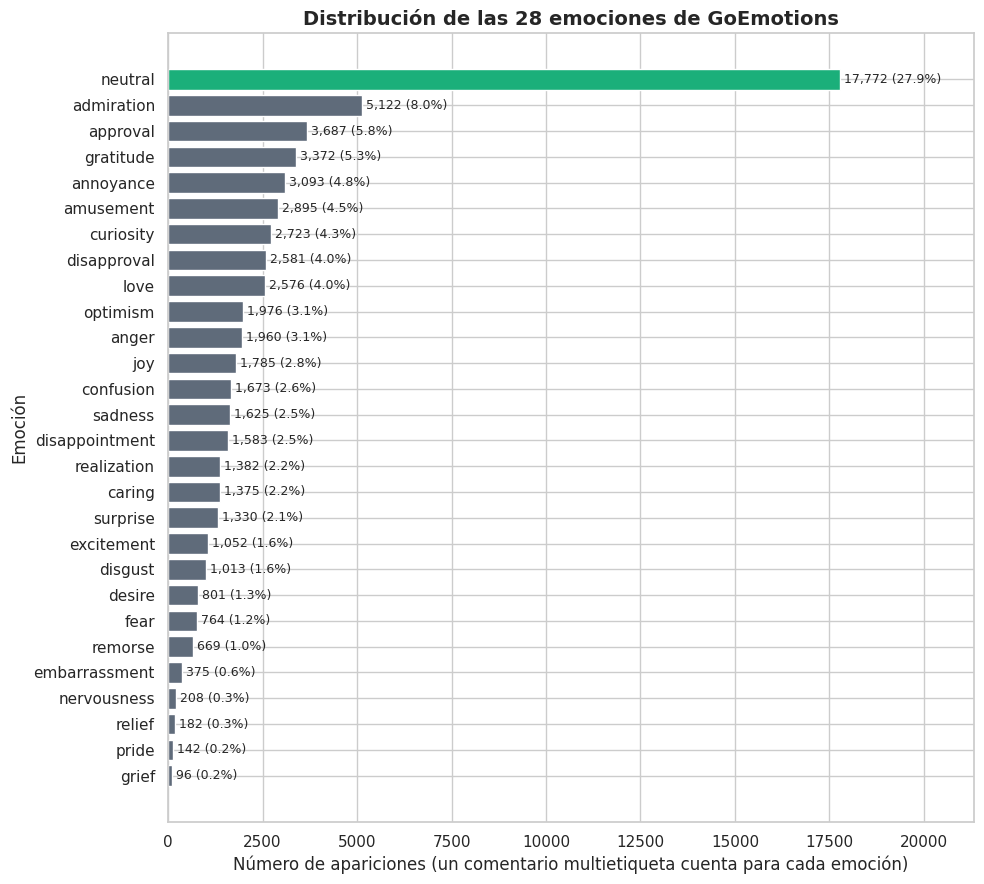

Total de apariciones: 63,812 en 54,263 comentarios
Ratio entre la emoción más frecuente y la menos frecuente: 185.1


In [23]:
conteo_emociones = df_etiquetado["emociones"].explode().value_counts()
total_apariciones = conteo_emociones.sum()

fig, ax = plt.subplots(figsize=(10, 9))
conteo_ordenado = conteo_emociones.sort_values()
colores = [PALETA_CLASES["neutral"] if e == "neutral" else COLOR_GENERAL for e in conteo_ordenado.index]
ax.barh(conteo_ordenado.index, conteo_ordenado.values, color=colores)
for i, valor in enumerate(conteo_ordenado.values):
    ax.text(valor, i, f" {valor:,} ({valor / total_apariciones:.1%})", va="center", fontsize=9)
ax.set_title("Distribución de las 28 emociones de GoEmotions")
ax.set_xlabel("Número de apariciones (un comentario multietiqueta cuenta para cada emoción)")
ax.set_ylabel("Emoción")
ax.set_xlim(0, conteo_ordenado.max() * 1.2)
plt.tight_layout()
plt.show()

print(f"Total de apariciones: {total_apariciones:,} en {len(df_etiquetado):,} comentarios")
print(f"Ratio entre la emoción más frecuente y la menos frecuente: "
      f"{conteo_emociones.iloc[0] / conteo_emociones.iloc[-1]:.1f}")

**Interpretación.** [COMPLETAR tras ejecutar: comentar el fuerte desbalance entre categorías. `neutral` es la categoría más frecuente, con [COMPLETAR] apariciones ([COMPLETAR] % del total), muy por encima de la segunda (`[COMPLETAR]`, [COMPLETAR] apariciones). Las categorías menos frecuentes (`[COMPLETAR]`, `[COMPLETAR]`) tienen apenas [COMPLETAR] apariciones, lo que da un ratio de [COMPLETAR] entre la más y la menos frecuente.]

#### 2.3.2 Análisis multietiqueta

Se cuenta cuántas etiquetas tiene cada comentario. Esto indica cuántos datos se conservarán al quedarse solo con los comentarios de una única etiqueta (subsección 2.4).

,comentarios,porcentaje
n_etiquetas,,
1,45446,83.75
2,8124,14.97
3,655,1.21
4,37,0.07
5,1,0.00


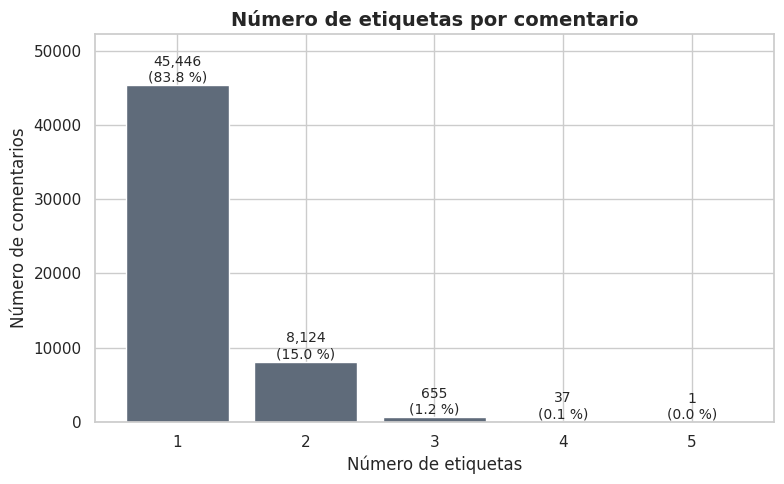

In [24]:
tabla_n_etiquetas = (
    df_etiquetado["n_etiquetas"].value_counts().sort_index()
    .rename_axis("n_etiquetas").to_frame("comentarios")
)
tabla_n_etiquetas["porcentaje"] = (tabla_n_etiquetas["comentarios"] / len(df_etiquetado) * 100).round(2)
display(tabla_n_etiquetas)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(tabla_n_etiquetas.index.astype(str), tabla_n_etiquetas["comentarios"], color=COLOR_GENERAL)
for barra, pct in zip(barras, tabla_n_etiquetas["porcentaje"]):
    ax.annotate(f"{int(barra.get_height()):,}\n({pct:.1f} %)",
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Número de etiquetas por comentario")
ax.set_xlabel("Número de etiquetas")
ax.set_ylabel("Número de comentarios")
ax.set_ylim(0, tabla_n_etiquetas["comentarios"].max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: el [COMPLETAR] % de los comentarios tiene una sola etiqueta, el [COMPLETAR] % tiene dos y solo el [COMPLETAR] % tiene tres o más. Comentar que la mayoría del dataset es de etiqueta única, por lo que filtrar los multietiqueta conserva la mayor parte de los datos.]

#### 2.3.3 Co-ocurrencias de emociones

Entre los comentarios multietiqueta se cuentan los pares de emociones que aparecen juntos. Esto sirve para evaluar la agrupación propuesta en 2.4: si dos emociones que se agruparán en la misma clase (por ejemplo, `annoyance` y `disappointment`, ambas en frustración) aparecen juntas con frecuencia, eso respalda que expresan estados parecidos. Si, en cambio, emociones de clases distintas aparecen juntas a menudo (por ejemplo, `anger` con `annoyance`), eso anticipa que esas clases serán difíciles de separar.

In [25]:
df_multi = df_etiquetado[df_etiquetado["n_etiquetas"] > 1]
conteo_pares = Counter(
    par
    for emociones in df_multi["emociones"]
    for par in itertools.combinations(sorted(emociones), 2)
)

top_pares = pd.DataFrame(
    [(a, b, n) for (a, b), n in conteo_pares.most_common(15)],
    columns=["emocion_1", "emocion_2", "comentarios"],
)
top_pares["clase_1"] = top_pares["emocion_1"].map(MAPEO_CLASES).fillna("(descartada)")
top_pares["clase_2"] = top_pares["emocion_2"].map(MAPEO_CLASES).fillna("(descartada)")
top_pares["misma_clase"] = (top_pares["clase_1"] == top_pares["clase_2"]) & (top_pares["clase_1"] != "(descartada)")
print(f"Comentarios multietiqueta: {len(df_multi):,}")
print("Top 15 de pares de emociones más frecuentes:")
display(top_pares)

Comentarios multietiqueta: 8,817
Top 15 de pares de emociones más frecuentes:


,emocion_1,emocion_2,comentarios,clase_1,clase_2,misma_clase
0,anger,annoyance,348,enojo,frustracion,False
1,admiration,gratitude,341,alegria,alegria,True
2,admiration,approval,298,alegria,alegria,True
3,approval,neutral,258,alegria,neutral,False
4,confusion,curiosity,253,confusion,(descartada),False
5,admiration,love,236,alegria,(descartada),False
6,annoyance,disapproval,222,frustracion,(descartada),False
7,annoyance,neutral,177,frustracion,neutral,False
8,disappointment,sadness,163,frustracion,(descartada),False
9,curiosity,neutral,162,(descartada),neutral,False


Para mirar en detalle las emociones que se usarán en el proyecto, el siguiente heatmap muestra las co-ocurrencias solo entre las 12 emociones que se agrupan en las cinco clases, ordenadas por clase. Los recuadros marcan los pares que quedan dentro de la misma clase.

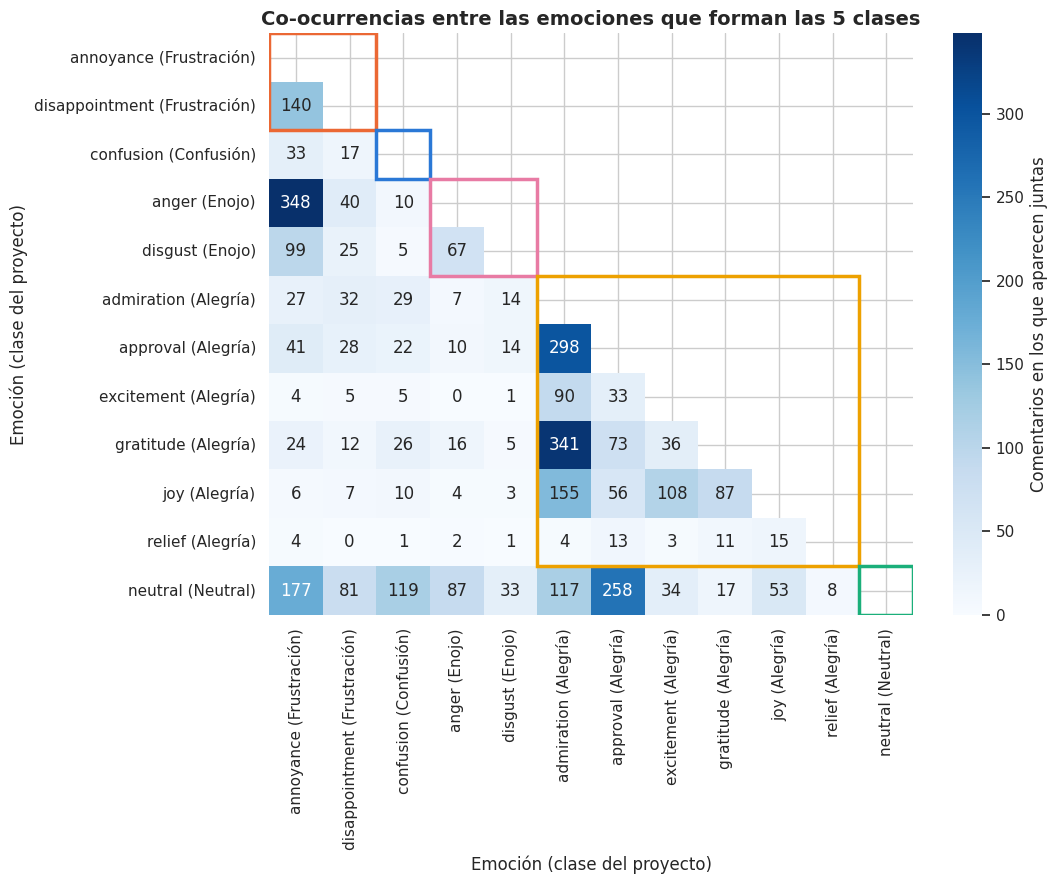

Pares de interés para la agrupación:
  annoyance + disappointment: 140 comentarios
  anger + disgust: 67 comentarios
  anger + annoyance: 348 comentarios
  annoyance + disgust: 99 comentarios
  admiration + gratitude: 341 comentarios
  excitement + joy: 108 comentarios


In [26]:
emociones_usadas = sorted(MAPEO_CLASES, key=lambda e: (ORDEN_CLASES.index(MAPEO_CLASES[e]), e))
matriz_coocurrencia = pd.DataFrame(0, index=emociones_usadas, columns=emociones_usadas)
for (a, b), n in conteo_pares.items():
    if a in MAPEO_CLASES and b in MAPEO_CLASES:
        matriz_coocurrencia.loc[a, b] += n
        matriz_coocurrencia.loc[b, a] += n

etiquetas_ejes = [f"{e} ({NOMBRES_CLASES[MAPEO_CLASES[e]]})" for e in emociones_usadas]
mascara = np.triu(np.ones_like(matriz_coocurrencia, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz_coocurrencia, mask=mascara, annot=True, fmt="d", cmap="Blues",
            xticklabels=etiquetas_ejes, yticklabels=etiquetas_ejes,
            cbar_kws={"label": "Comentarios en los que aparecen juntas"}, ax=ax)

# Recuadros que delimitan los pares de emociones de una misma clase
inicio = 0
for clase in ORDEN_CLASES:
    tamano = sum(MAPEO_CLASES[e] == clase for e in emociones_usadas)
    ax.add_patch(plt.Rectangle((inicio, inicio), tamano, tamano, fill=False,
                               edgecolor=PALETA_CLASES[clase], linewidth=2.5))
    inicio += tamano

ax.set_title("Co-ocurrencias entre las emociones que forman las 5 clases")
ax.set_xlabel("Emoción (clase del proyecto)")
ax.set_ylabel("Emoción (clase del proyecto)")
plt.tight_layout()
plt.show()

print("Pares de interés para la agrupación:")
for a, b in [("annoyance", "disappointment"), ("anger", "disgust"), ("anger", "annoyance"),
             ("annoyance", "disgust"), ("admiration", "gratitude"), ("excitement", "joy")]:
    par = tuple(sorted((a, b)))
    print(f"  {a} + {b}: {conteo_pares.get(par, 0):,} comentarios")

**Interpretación.** [COMPLETAR tras ejecutar: indicar qué pares dominan el top 15 (en GoEmotions suelen aparecer muchos pares con `neutral` y entre emociones positivas como `admiration` y `gratitude`). Comentar si `annoyance` y `disappointment` aparecen juntas ([COMPLETAR] comentarios), lo que respalda agruparlas en frustración, y cuántas veces aparecen `anger` y `annoyance` juntas ([COMPLETAR] comentarios), lo que indica que la frontera entre enojo y frustración es difusa. Lo mismo para `anger` y `disgust` ([COMPLETAR]), que forman la clase enojo.]

**Cifras clave de 2.3**

- Total de apariciones de emociones: [COMPLETAR] en [COMPLETAR] comentarios.
- Comentarios con una sola etiqueta: [COMPLETAR] ([COMPLETAR] %).
- Comentarios multietiqueta: [COMPLETAR].

### 2.4 Filtrado y agrupación en las 5 clases del proyecto

#### 2.4.1 Filtrado de comentarios con una única etiqueta

Se conservan solo los comentarios que tienen **una única etiqueta**. Hay dos razones:

1. **Evitar ejemplos ambiguos.** Un comentario anotado a la vez con, por ejemplo, `annoyance` y `joy` no tiene una emoción dominante clara, y usarlo como ejemplo de una sola clase introduciría ruido en el entrenamiento.
2. **Convertir el problema en clasificación multiclase.** El clasificador del tutor debe asignar una emoción a cada mensaje, así que cada ejemplo de entrenamiento debe tener exactamente una etiqueta.

Como se vio en 2.3.2, la gran mayoría de los comentarios son de etiqueta única, de modo que el filtro conserva la mayor parte de los datos.

In [27]:
df_una_etiqueta = df_etiquetado[df_etiquetado["n_etiquetas"] == 1].copy()
df_una_etiqueta["emocion_original"] = df_una_etiqueta["emociones"].str[0]

print(f"Filas antes del filtro: {len(df_etiquetado):,}")
print(f"Filas con una única etiqueta: {len(df_una_etiqueta):,} "
      f"({len(df_una_etiqueta) / len(df_etiquetado):.1%})")

Filas antes del filtro: 54,263
Filas con una única etiqueta: 45,446 (83.8%)


#### 2.4.2 Agrupación de las emociones en las 5 clases

Las emociones originales se agrupan en las cinco clases del proyecto según la siguiente tabla:

| Clase del proyecto | Emociones originales de GoEmotions |
|---|---|
| frustracion | annoyance, disappointment |
| confusion | confusion |
| enojo | anger, disgust |
| alegria | joy, gratitude, admiration, approval, relief, excitement |
| neutral | neutral |

Las filas cuya emoción no aparece en la tabla se descartan.

In [28]:
df_5clases = df_una_etiqueta.copy()
df_5clases["clase"] = df_5clases["emocion_original"].map(MAPEO_CLASES)

df_descartado = df_5clases[df_5clases["clase"].isna()]
df_5clases = df_5clases.dropna(subset=["clase"]).reset_index(drop=True)

print(f"Filas descartadas por no estar en la tabla: {len(df_descartado):,}")
print(f"Filas tras agrupar en 5 clases: {len(df_5clases):,}")
print("\nEmociones descartadas (comentarios de una sola etiqueta):")
display(df_descartado["emocion_original"].value_counts().rename_axis("emocion").to_frame("comentarios"))

Filas descartadas por no estar en la tabla: 13,868
Filas tras agrupar en 5 clases: 31,578

Emociones descartadas (comentarios de una sola etiqueta):


,comentarios
emocion,
amusement,2046
disapproval,1809
love,1760
curiosity,1729
optimism,1087
sadness,1003
surprise,902
caring,831
realization,749


**Justificación de los descartes.** Se conservan solo las emociones que corresponden a los estados emocionales que el tutor necesita reconocer. Las demás se descartan porque no aportan a ninguna de las cinco clases o porque introducirían ruido. Los casos más discutibles son:

- **`curiosity`**: en un contexto educativo la curiosidad indica interés y podría parecer relevante. Sin embargo, en el texto se expresa casi siempre con preguntas, igual que la confusión, y el modelo tendría muchas dificultades para distinguir "pregunto porque me interesa" de "pregunto porque no entiendo". Se excluye para no introducir ruido en la clase confusión.
- **`sadness`, `fear` y `nervousness`**: aunque la ansiedad o el desánimo pueden darse al estudiar, en Reddit estas emociones se refieren sobre todo a temas personales (duelo, enfermedades, miedos), no a dificultades de aprendizaje. Incluirlas haría que las clases aprendieran vocabulario de un dominio muy distinto al del tutor.
- **Otras emociones** como `amusement`, `love`, `caring`, `optimism`, `surprise` o `disapproval` no corresponden de forma directa a ninguna de las cinco clases, o lo hacen de forma ambigua (por ejemplo, `disapproval` puede expresar desacuerdo sin frustración ni enojo).

In [29]:
resumen_filtrado = pd.DataFrame({
    "paso": [
        "Total original (todos los splits)",
        "Con una única etiqueta",
        "Tras agrupar en 5 clases",
    ],
    "filas": [len(df_crudo), len(df_una_etiqueta), len(df_5clases)],
})
resumen_filtrado["% del total original"] = (resumen_filtrado["filas"] / len(df_crudo) * 100).round(2)
resumen_filtrado

,paso,filas,% del total original
0,Total original (todos los splits),54263,100.00
1,Con una única etiqueta,45446,83.75
2,Tras agrupar en 5 clases,31578,58.19


#### 2.4.3 Composición interna de cada clase

Se revisa cuántos ejemplos aporta cada emoción original a su clase. Si una clase depende casi por completo de una sola emoción, el modelo aprenderá en realidad esa emoción y no el concepto más amplio de la clase.

,clase,emocion_original,comentarios,% dentro de la clase
0,frustracion,annoyance,1809,67.1
1,frustracion,disappointment,888,32.9
2,confusion,confusion,1057,100.0
3,enojo,anger,1265,66.6
4,enojo,disgust,635,33.4
5,alegria,admiration,3384,34.2
6,alegria,gratitude,2378,24.0
7,alegria,approval,2367,23.9
8,alegria,joy,1052,10.6
9,alegria,excitement,619,6.3


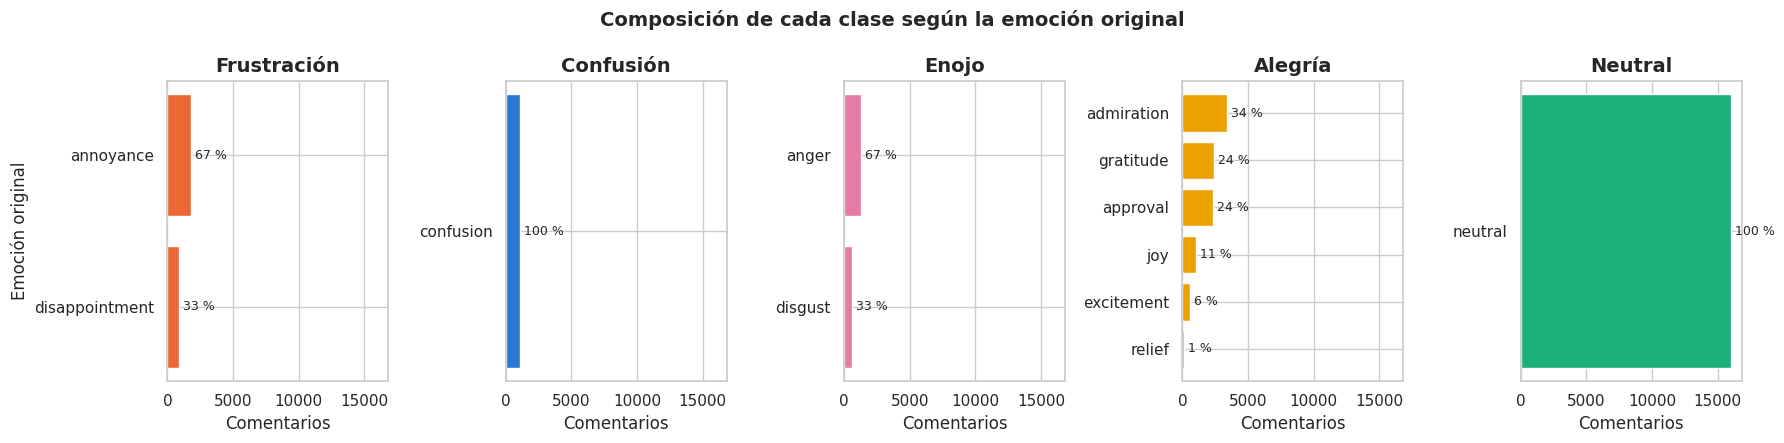

In [30]:
composicion = (
    df_5clases.groupby(["clase", "emocion_original"]).size()
    .rename("comentarios").reset_index()
)
composicion["% dentro de la clase"] = (
    composicion["comentarios"] / composicion.groupby("clase")["comentarios"].transform("sum") * 100
).round(1)
composicion["clase"] = pd.Categorical(composicion["clase"], categories=ORDEN_CLASES, ordered=True)
composicion = composicion.sort_values(["clase", "comentarios"], ascending=[True, False]).reset_index(drop=True)
display(composicion)

fig, ejes = plt.subplots(1, len(ORDEN_CLASES), figsize=(18, 4.5), sharex=True)
for ax, clase in zip(ejes, ORDEN_CLASES):
    datos = composicion[composicion["clase"] == clase].sort_values("comentarios")
    ax.barh(datos["emocion_original"], datos["comentarios"], color=PALETA_CLASES[clase])
    for i, (valor, pct) in enumerate(zip(datos["comentarios"], datos["% dentro de la clase"])):
        ax.text(valor, i, f" {pct:.0f} %", va="center", fontsize=9)
    ax.set_title(NOMBRES_CLASES[clase])
    ax.set_xlabel("Comentarios")
ejes[0].set_ylabel("Emoción original")
fig.suptitle("Composición de cada clase según la emoción original", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: indicar qué emoción domina cada clase. Por ejemplo, en alegría comentar el peso de `admiration` y `gratitude` frente a `relief`, que aporta muy pocos ejemplos; en frustración, la proporción entre `annoyance` y `disappointment`; en enojo, la proporción entre `anger` y `disgust`. Señalar si alguna clase depende casi por completo de una sola emoción ([COMPLETAR] %), lo que se tendrá en cuenta al submuestrear en 2.10.]

**Cifras clave de 2.4**

- Total original: [COMPLETAR] filas → con una única etiqueta: [COMPLETAR] → tras agrupar en 5 clases: [COMPLETAR].
- Filas descartadas por emoción fuera de la tabla: [COMPLETAR].

### 2.5 Limpieza de los datos

Se elimina el ruido evidente y se documenta cuántas filas se pierden en cada paso. Se trabaja sobre una copia (`df_limpio`), de modo que `df_5clases` se conserva intacto.

**Importante:** los textos se representarán más adelante con embeddings de un modelo Sentence-BERT preentrenado. Estos modelos se entrenaron con texto natural, así que **no** se eliminan stopwords, no se aplica *stemming* ni se pasa el texto a minúsculas: el encoder necesita el texto tal como lo escribiría una persona, con sus mayúsculas, signos de puntuación y palabras funcionales.

#### 2.5.1 Duplicados exactos y conflictos de etiquetas

Se buscan textos en español (`text_es`) repetidos. Hay dos casos:

- **Duplicados con la misma clase**: no aportan información nueva y, si se dejan, el mismo texto podría quedar a la vez en entrenamiento y en validación durante la validación cruzada, lo que inflaría las métricas. Se conserva una sola copia.
- **Duplicados con clases distintas (conflicto de etiquetas)**: el mismo texto aparece con dos clases diferentes. No es posible saber cuál es la correcta, así que se eliminan todas sus copias.

In [31]:
df_limpio = df_5clases.copy()
filas_inicio_limpieza = len(df_limpio)

clases_por_texto = df_limpio.groupby("text_es")["clase"].nunique()
textos_en_conflicto = clases_por_texto[clases_por_texto > 1].index

print(f"Filas con texto repetido (todas las copias): {df_limpio['text_es'].duplicated(keep=False).sum():,}")
print(f"Textos distintos con conflicto de clases: {len(textos_en_conflicto):,}")

if len(textos_en_conflicto) > 0:
    print("\nEjemplos de conflictos de etiquetas:")
    display(
        df_limpio[df_limpio["text_es"].isin(textos_en_conflicto)]
        .sort_values("text_es")[["text_es", "text", "emocion_original", "clase"]]
        .head(10)
    )

Filas con texto repetido (todas las copias): 536
Textos distintos con conflicto de clases: 37

Ejemplos de conflictos de etiquetas:


,text_es,text,emocion_original,clase
17698,Bien dicho.,Well said.,gratitude,alegria
25497,Bien dicho.,Well fucking said.,neutral,neutral
17581,"Buena historia, hermano.",Cool story bro,admiration,alegria
23269,"Buena historia, hermano.",cool story bro,admiration,alegria
1181,"Buena historia, hermano.",Cool story bro,admiration,alegria
6048,"Buena historia, hermano.",cool story bro,neutral,neutral
25671,Cierto.,true that.,approval,alegria
6802,Cierto.,True that.,neutral,neutral
8219,De nada.,You're welcome,neutral,neutral
25775,De nada.,Your welcome.,gratitude,alegria


In [32]:
# 1) Eliminar todas las copias de los textos con conflicto de clases
filas_antes = len(df_limpio)
df_limpio = df_limpio[~df_limpio["text_es"].isin(textos_en_conflicto)]
eliminadas_conflicto = filas_antes - len(df_limpio)

# 2) Eliminar los duplicados restantes (misma clase), conservando la primera aparición
filas_antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates(subset="text_es", keep="first")
eliminadas_duplicados = filas_antes - len(df_limpio)

print(f"Filas eliminadas por conflicto de etiquetas: {eliminadas_conflicto:,}")
print(f"Filas eliminadas por duplicado exacto: {eliminadas_duplicados:,}")
print(f"Filas restantes: {len(df_limpio):,}")

Filas eliminadas por conflicto de etiquetas: 110
Filas eliminadas por duplicado exacto: 282
Filas restantes: 31,186


#### 2.5.2 Textos vacíos o muy cortos

Se eliminan los textos vacíos y los que tienen **menos de 3 palabras**. Con una o dos palabras ("Gracias", "Lol", "[NAME] jaja") casi nunca hay contexto suficiente para reconocer una emoción con seguridad, y en un dataset traducido automáticamente estos fragmentos suelen ser los peor traducidos, porque son interjecciones, abreviaturas o jerga. Además, los mensajes que un estudiante escribe a un tutor para expresar confusión o frustración suelen ser frases completas. El umbral de 3 palabras es deliberadamente bajo para eliminar solo los casos claramente insuficientes.

In [33]:
UMBRAL_PALABRAS = 3

n_palabras = df_limpio["text_es"].fillna("").str.split().str.len()
mascara_cortos = n_palabras < UMBRAL_PALABRAS

print(f"Textos vacíos: {(n_palabras == 0).sum():,}")
print(f"Textos con menos de {UMBRAL_PALABRAS} palabras (incluye vacíos): {mascara_cortos.sum():,}")
print("\nDistribución por clase de los textos cortos:")
display(df_limpio.loc[mascara_cortos, "clase"].value_counts().reindex(ORDEN_CLASES, fill_value=0).to_frame("textos cortos"))

print("Ejemplos de textos cortos que se eliminan:")
display(df_limpio.loc[mascara_cortos, ["text_es", "text", "clase"]].sample(
    min(10, mascara_cortos.sum()), random_state=SEMILLA))

filas_antes = len(df_limpio)
df_limpio = df_limpio[~mascara_cortos]
eliminadas_cortos = filas_antes - len(df_limpio)
print(f"Filas eliminadas por ser vacías o muy cortas: {eliminadas_cortos:,}")

Textos vacíos: 0
Textos con menos de 3 palabras (incluye vacíos): 1,010

Distribución por clase de los textos cortos:


,textos cortos
clase,
frustracion,34
confusion,15
enojo,84
alegria,335
neutral,542


Ejemplos de textos cortos que se eliminan:


,text_es,text,clase
19602,Todavía molesto.,Still annoying.,frustracion
24675,Te mataré.,I'll kill you.,enojo
21524,"¿Ja, ja?",Ha ha?,neutral
16017,¡FBI abra!,FBI OPEN UP!,neutral
16326,Mierda. Eso.,Fuck. That.,enojo
20702,¡Muy apreciado!,Much appreciated !,alegria
17111,¡Debo romperte!,I must break you!,enojo
16511,Bien enmarcado.,Nicely framed.,alegria
10038,Completamente asqueroso.,Completely disgusting.,enojo
1726,¡Jodido DIN!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,FUCKING DIN!!!,enojo


Filas eliminadas por ser vacías o muy cortas: 1,010


#### 2.5.3 Marcadores de Reddit y URLs

El dataset original anonimiza los nombres de personas y de religiones con marcadores entre corchetes, como `[NAME]` o `[RELIGION]`. Al traducir, el sistema a veces los dejó en inglés y a veces los tradujo (por ejemplo, `[NOMBRE]` o `[RELIGIÓN]`), así que se cuentan todas sus variantes. También se buscan URLs.

In [34]:
PATRON_MARCADOR = r"\[[^\[\]\s]{2,20}\]"
PATRON_URL = r"https?://\S+|www\.\S+"

marcadores = df_limpio["text_es"].str.findall(PATRON_MARCADOR).explode().dropna()
print("Marcadores entre corchetes encontrados en text_es:")
display(marcadores.value_counts().rename_axis("marcador").to_frame("apariciones").head(20))
print(f"Textos con al menos un marcador: {df_limpio['text_es'].str.contains(PATRON_MARCADOR).sum():,}")
print(f"Textos con al menos una URL: {df_limpio['text_es'].str.contains(PATRON_URL).sum():,}")

Marcadores entre corchetes encontrados en text_es:


,apariciones
marcador,
[NAME],5096
[NOMBRE],473
[RELIGION],47
[RELIGIÓN],26
[NAM],3
[goshdarn],1
[get_user_id],1
[{respuesta}],1
[...],1


Textos con al menos un marcador: 4,347
Textos con al menos una URL: 0


**Decisión.** Los marcadores **se conservan, pero se normalizan** a una única forma en español:

- `[NAME]`, `[NAM]` y `[NOMBRE]` → `[NOMBRE]`
- `[RELIGION]` y `[RELIGIÓN]` → `[RELIGIÓN]`

Se conservan porque forman parte de la estructura de la frase (por ejemplo, "Gracias, [NOMBRE]"), y eliminarlos dejaría oraciones incompletas que el encoder interpretaría peor. Se normalizan porque tener dos o tres variantes del mismo marcador hace que textos equivalentes produzcan embeddings distintos solo por un detalle de la traducción. Se elige la forma en español porque el resto del texto está en español. Los demás textos entre corchetes que aparecen pocas veces (por ejemplo, `[risas]`) son palabras normales del comentario y no se modifican.

Las URLs, si aparecen, se reemplazan por el marcador `[URL]`, porque su contenido (direcciones concretas) no aporta información emocional. El número de textos con URL se indica en la celda anterior.

In [35]:
REEMPLAZOS_MARCADORES = {
    r"\[(?:NAME|NAM|NOMBRE)\]": "[NOMBRE]",
    r"\[(?:RELIGION|RELIGIÓN)\]": "[RELIGIÓN]",
}

df_limpio = df_limpio.copy()
for patron, reemplazo in REEMPLAZOS_MARCADORES.items():
    df_limpio["text_es"] = df_limpio["text_es"].str.replace(patron, reemplazo, regex=True)
df_limpio["text_es"] = df_limpio["text_es"].str.replace(PATRON_URL, "[URL]", regex=True)

marcadores_despues = df_limpio["text_es"].str.findall(PATRON_MARCADOR).explode().dropna()
print("Marcadores más frecuentes después de normalizar:")
display(marcadores_despues.value_counts().rename_axis("marcador").to_frame("apariciones").head(5))

Marcadores más frecuentes después de normalizar:


,apariciones
marcador,
[NOMBRE],5572
[RELIGIÓN],73
[goshdarn],1
[get_user_id],1
[{respuesta}],1


La normalización puede crear nuevos duplicados (por ejemplo, "Gracias [NAME]" y "Gracias [NOMBRE]" pasan a ser el mismo texto), así que se repite la eliminación de duplicados y conflictos.

In [36]:
clases_por_texto = df_limpio.groupby("text_es")["clase"].nunique()
textos_en_conflicto_2 = clases_por_texto[clases_por_texto > 1].index

filas_antes = len(df_limpio)
df_limpio = df_limpio[~df_limpio["text_es"].isin(textos_en_conflicto_2)]
df_limpio = df_limpio.drop_duplicates(subset="text_es", keep="first").reset_index(drop=True)
eliminadas_normalizacion = filas_antes - len(df_limpio)

print(f"Filas eliminadas por duplicados creados al normalizar: {eliminadas_normalizacion:,}")
print(f"Filas restantes: {len(df_limpio):,}")

Filas eliminadas por duplicados creados al normalizar: 0
Filas restantes: 30,176


#### 2.5.4 Resumen de la limpieza

In [37]:
resumen_limpieza = pd.DataFrame({
    "paso": [
        "Filas al inicio de la limpieza",
        "Eliminadas por conflicto de etiquetas",
        "Eliminadas por duplicado exacto",
        f"Eliminadas por tener menos de {UMBRAL_PALABRAS} palabras",
        "Eliminadas por duplicados tras normalizar marcadores",
        "Filas tras la limpieza",
    ],
    "filas": [
        filas_inicio_limpieza,
        eliminadas_conflicto,
        eliminadas_duplicados,
        eliminadas_cortos,
        eliminadas_normalizacion,
        len(df_limpio),
    ],
})
resumen_limpieza

,paso,filas
0,Filas al inicio de la limpieza,31578
1,Eliminadas por conflicto de etiquetas,110
2,Eliminadas por duplicado exacto,282
3,Eliminadas por tener menos de 3 palabras,1010
4,Eliminadas por duplicados tras normalizar marcadores,0
5,Filas tras la limpieza,30176


**Cifras clave de 2.5**

- Filas al inicio de la limpieza: [COMPLETAR] → filas tras la limpieza: [COMPLETAR] ([COMPLETAR] eliminadas, [COMPLETAR] %).
- Conflictos de etiquetas: [COMPLETAR] textos distintos ([COMPLETAR] filas).
- Duplicados exactos: [COMPLETAR]. Textos con menos de 3 palabras: [COMPLETAR]. Duplicados tras normalizar: [COMPLETAR].
- Textos con marcadores: [COMPLETAR]. Textos con URL: [COMPLETAR].

### 2.6 Distribución de clases

Se cuantifica el desbalance entre las cinco clases, porque condiciona tanto la métrica de evaluación como la estrategia de balanceo.

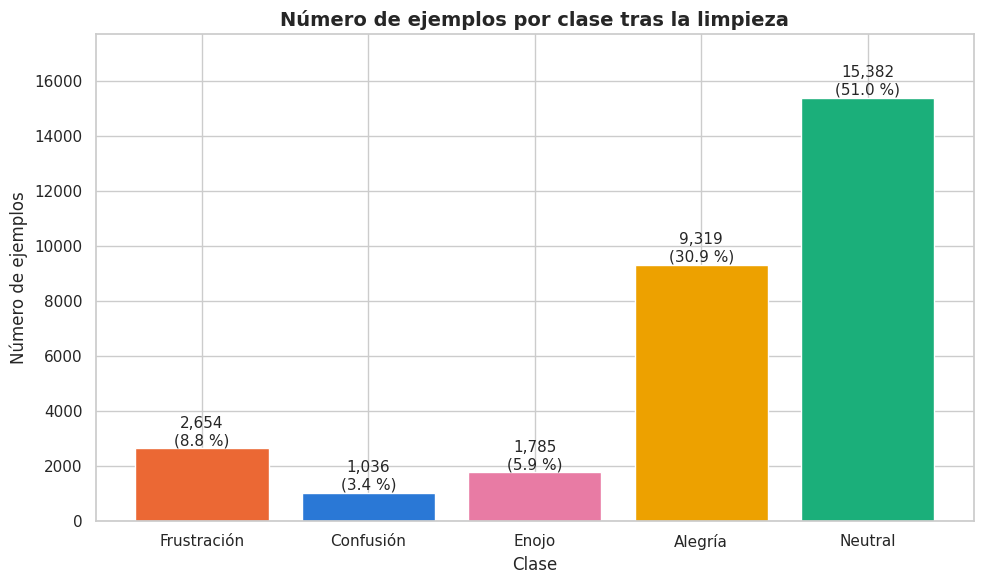

Clase mayoritaria: neutral (15,382 ejemplos)
Clase minoritaria: confusion (1,036 ejemplos)
Ratio de desbalance (mayoritaria / minoritaria): 14.8


In [38]:
conteo_clases = df_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
porcentaje_clases = conteo_clases / conteo_clases.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar([NOMBRES_CLASES[c] for c in ORDEN_CLASES], conteo_clases.values,
                color=[PALETA_CLASES[c] for c in ORDEN_CLASES])
for barra, n, pct in zip(barras, conteo_clases.values, porcentaje_clases.values):
    ax.annotate(f"{n:,}\n({pct:.1f} %)", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=11)
ax.set_title("Número de ejemplos por clase tras la limpieza")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de ejemplos")
ax.set_ylim(0, conteo_clases.max() * 1.15)
plt.tight_layout()
plt.show()

ratio_desbalance = conteo_clases.max() / conteo_clases.min()
print(f"Clase mayoritaria: {conteo_clases.idxmax()} ({conteo_clases.max():,} ejemplos)")
print(f"Clase minoritaria: {conteo_clases.idxmin()} ({conteo_clases.min():,} ejemplos)")
print(f"Ratio de desbalance (mayoritaria / minoritaria): {ratio_desbalance:.1f}")

**Interpretación.** [COMPLETAR tras ejecutar: la clase mayoritaria es `[COMPLETAR]` con [COMPLETAR] ejemplos ([COMPLETAR] %) y la minoritaria es `[COMPLETAR]` con [COMPLETAR] ejemplos ([COMPLETAR] %), lo que da un ratio de desbalance de [COMPLETAR].]

Este desbalance tiene dos consecuencias para el resto del proyecto:

- **La exactitud (*accuracy*) no es una métrica adecuada.** Un clasificador que prediga siempre la clase mayoritaria obtendría una exactitud de [COMPLETAR] % sin haber aprendido nada, y fallaría precisamente en las clases minoritarias, que son las más importantes para el tutor (frustración, confusión, enojo). Por eso la métrica principal será el **F1-macro**, que calcula el F1 de cada clase por separado y los promedia sin ponderar, de modo que todas las clases pesan lo mismo sin importar cuántos ejemplos tengan.
- **Se necesita una estrategia de balanceo**, ya sea submuestreo con un tope de ejemplos por clase, pesos por clase (`class_weight`) en los clasificadores, o ambas. La decisión final se toma en la subsección 2.10.

### 2.7 Análisis de la longitud de los textos

Se caracteriza la longitud de los textos por dos motivos: comprobar si la longitud por sí sola ya distingue las clases (si así fuera, el modelo podría aprender un atajo en lugar del contenido) y verificar que los textos caben en el límite de entrada del encoder.

In [39]:
df_limpio["n_palabras"] = df_limpio["text_es"].str.split().str.len()
df_limpio["n_caracteres"] = df_limpio["text_es"].str.len()

def percentil(q):
    funcion = lambda serie: serie.quantile(q)
    funcion.__name__ = f"p{int(q * 100)}"
    return funcion

estadisticos_longitud = (
    df_limpio.groupby("clase")[["n_palabras", "n_caracteres"]]
    .agg(["mean", "median", "std", "min", "max", percentil(0.25), percentil(0.75), percentil(0.95)])
    .reindex(ORDEN_CLASES)
    .round(1)
)
estadisticos_longitud.columns = estadisticos_longitud.columns.set_names(["medida", "estadístico"])
estadisticos_longitud = estadisticos_longitud.rename(columns={
    "mean": "media", "median": "mediana", "std": "desv_est", "min": "mínimo", "max": "máximo",
}, level=1)
display(estadisticos_longitud)

print("Estadísticos generales (todas las clases):")
display(df_limpio[["n_palabras", "n_caracteres"]].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(1))

medida      n_palabras                                                   \
estadístico      media mediana desv_est mínimo máximo   p25   p75   p95   
clase                                                                     
frustracion       15.4    14.0     20.9      3    533   9.0  20.0  26.0   
confusion         17.2    15.0     29.6      3    529  10.0  20.0  26.0   
enojo             13.7    12.0     19.4      3    527   7.0  18.0  26.0   
alegria           15.5    12.0     38.2      3    538   7.0  18.0  25.0   
neutral           14.4    12.0     22.5      3    535   7.0  19.0  26.0   

medida      n_caracteres                                                     
estadístico        media mediana desv_est mínimo máximo   p25    p75    p95  
clase                                                                        
frustracion         85.3    80.0     55.6     10   1168  52.0  112.0  153.0  
confusion           88.2    82.0     69.3     12   1119  53.0  113.0  152.2  
enojo               74.9    67.0     54.1     11   1100  38.0  101.0  148.8  
alegria             80.0    70.0     84.8      9   1168  41.0  102.0  149.0  
neutral             78.7    72.0     59.4      5   1152  42.0  106.0  151.0

Estadísticos generales (todas las clases):


,n_palabras,n_caracteres
count,30176.0,30176.0
mean,14.9,79.8
std,28.3,68.1
min,3.0,5.0
25%,7.0,43.0
50%,12.0,72.0
75%,18.0,106.0
95%,26.0,151.0
max,538.0,1168.0


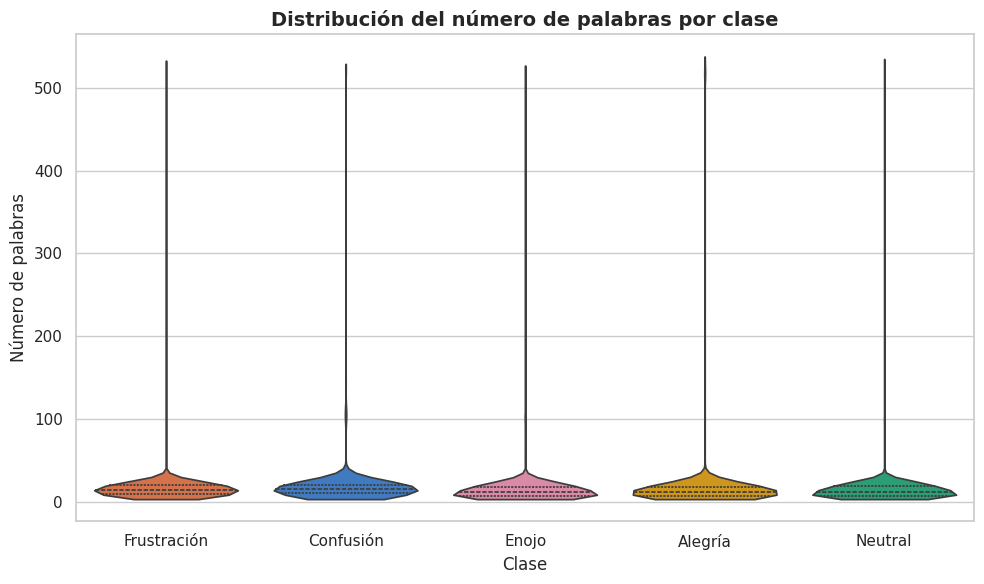

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=df_limpio, x="clase", y="n_palabras", order=ORDEN_CLASES,
               hue="clase", palette=PALETA_CLASES, legend=False, cut=0, inner="quartile", ax=ax)
ax.set_xticks(range(len(ORDEN_CLASES)))
ax.set_xticklabels([NOMBRES_CLASES[c] for c in ORDEN_CLASES])
ax.set_title("Distribución del número de palabras por clase")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de palabras")
plt.tight_layout()
plt.show()

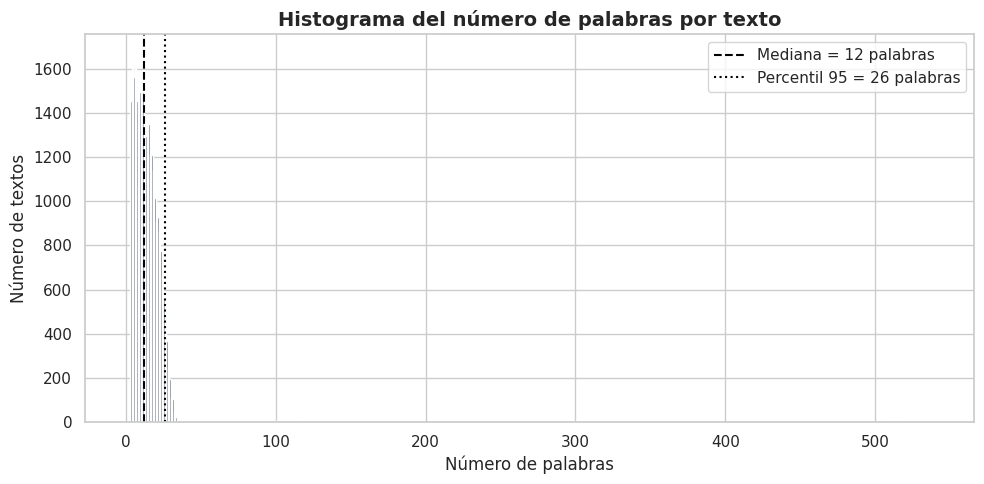

Percentil 95 del número de palabras: 26
Máximo número de palabras: 538
Incluso suponiendo 2 tokens por palabra, el percentil 95 equivale a unos 52 tokens (límite habitual del encoder: 128 tokens).
Textos con más de 64 palabras (posible truncación): 154


In [41]:
p95_palabras = df_limpio["n_palabras"].quantile(0.95)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_limpio["n_palabras"], bins=range(0, df_limpio["n_palabras"].max() + 2), color=COLOR_GENERAL)
ax.axvline(df_limpio["n_palabras"].median(), color="black", linestyle="--", linewidth=1.5,
           label=f"Mediana = {df_limpio['n_palabras'].median():.0f} palabras")
ax.axvline(p95_palabras, color="black", linestyle=":", linewidth=1.5,
           label=f"Percentil 95 = {p95_palabras:.0f} palabras")
ax.set_title("Histograma del número de palabras por texto")
ax.set_xlabel("Número de palabras")
ax.set_ylabel("Número de textos")
ax.legend()
plt.tight_layout()
plt.show()

LIMITE_TOKENS = 128
print(f"Percentil 95 del número de palabras: {p95_palabras:.0f}")
print(f"Máximo número de palabras: {df_limpio['n_palabras'].max()}")
print(f"Incluso suponiendo 2 tokens por palabra, el percentil 95 equivale a unos {2 * p95_palabras:.0f} tokens "
      f"(límite habitual del encoder: {LIMITE_TOKENS} tokens).")
print(f"Textos con más de {LIMITE_TOKENS // 2} palabras (posible truncación): "
      f"{(df_limpio['n_palabras'] > LIMITE_TOKENS // 2).sum():,}")

**Interpretación.** [COMPLETAR tras ejecutar: los textos son cortos, con una mediana de [COMPLETAR] palabras y un percentil 95 de [COMPLETAR] palabras. Comentar si alguna clase es notablemente más larga o más corta (por ejemplo, si `neutral` o `alegria` tienen textos más cortos que `frustracion`); si las distribuciones se solapan mucho, la longitud por sí sola no distingue las clases y el modelo tendrá que basarse en el contenido.]

**Truncación.** Los modelos Sentence-BERT suelen truncar la entrada a 128 tokens. El número exacto de tokens depende del tokenizador del encoder que se elija, pero en español una palabra suele dividirse en uno o dos tokens. Con un percentil 95 de [COMPLETAR] palabras (unos [COMPLETAR] tokens en el peor caso), la gran mayoría de los textos cabe completa en el límite y la truncación no será un problema; solo [COMPLETAR] textos superan las 64 palabras.

**Cifras clave de 2.7**

- Mediana: [COMPLETAR] palabras / [COMPLETAR] caracteres. Percentil 95: [COMPLETAR] palabras. Máximo: [COMPLETAR] palabras.

### 2.8 Análisis del vocabulario por clase

Se analiza qué palabras caracterizan a cada clase, para comprobar que el contenido es coherente con la etiqueta y detectar vocabulario de dominios ajenos al educativo.

**Normalización solo para el análisis.** Para contar palabras de forma significativa, aquí (y solo aquí, no para el modelo) se aplica una normalización mínima: paso a minúsculas, eliminación de la puntuación y de los números, eliminación de los marcadores (`[NOMBRE]`, `[RELIGIÓN]`, `[URL]`) y eliminación de las *stopwords* en español de la lista de spaCy. Sin esto, las palabras más frecuentes de todas las clases serían "de", "que" o "la", que no dicen nada sobre la emoción. El texto que se usará para el modelo (`text_es`) no se modifica.

In [42]:
from spacy.lang.es.stop_words import STOP_WORDS

STOPWORDS_ES = {palabra.lower() for palabra in STOP_WORDS}

def normalizar_para_analisis(texto):
    # Normalización mínima, solo para el análisis de vocabulario
    texto = re.sub(PATRON_MARCADOR, " ", texto)      # quitar marcadores como [NOMBRE]
    texto = texto.lower()
    texto = re.sub(r"[^\w\s]|\d|_", " ", texto)      # quitar puntuación, números y guiones bajos
    return [palabra for palabra in texto.split() if palabra not in STOPWORDS_ES and len(palabra) > 1]

df_vocabulario = df_limpio[["text_es", "clase"]].copy()
df_vocabulario["tokens"] = df_vocabulario["text_es"].apply(normalizar_para_analisis)
df_vocabulario["texto_normalizado"] = df_vocabulario["tokens"].str.join(" ")

print(f"Stopwords en español (spaCy): {len(STOPWORDS_ES)}")
df_vocabulario[["text_es", "texto_normalizado"]].sample(5, random_state=SEMILLA)

Stopwords en español (spaCy): 521


,text_es,texto_normalizado
15694,prisionero del momento pero ese es mi pase favorito de Jok nunca. El grado de dificultad era de locos.,prisionero momento pase favorito jok grado dificultad locos
27658,EL ENVASE RUNS PROFUNDE Y DURA. Yo compartiría mi equipo de KRAFT Y CHEESE contigo cualquier día. AROUOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOO,envase runs profunde dura compartiría equipo kraft cheese arouooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooooo
5346,Sí. Hazle saber. Extraño incómodo NOPE se hace mejor en línea que en persona,hazle extraño incómodo nope línea persona
25992,"Personalmente creo que [NOMBRE] es asexual, otros personajes en situaciones similares todos tienen pistas hacia la homosexualidad, pero no puedo recordar ninguna para [NOMBRE].",personalmente asexual personajes situaciones similares pistas homosexualidad recordar
19550,"Gracias por su preocupación, colega conservador.",gracias preocupación colega conservador


#### 2.8.1 Palabras más frecuentes por clase

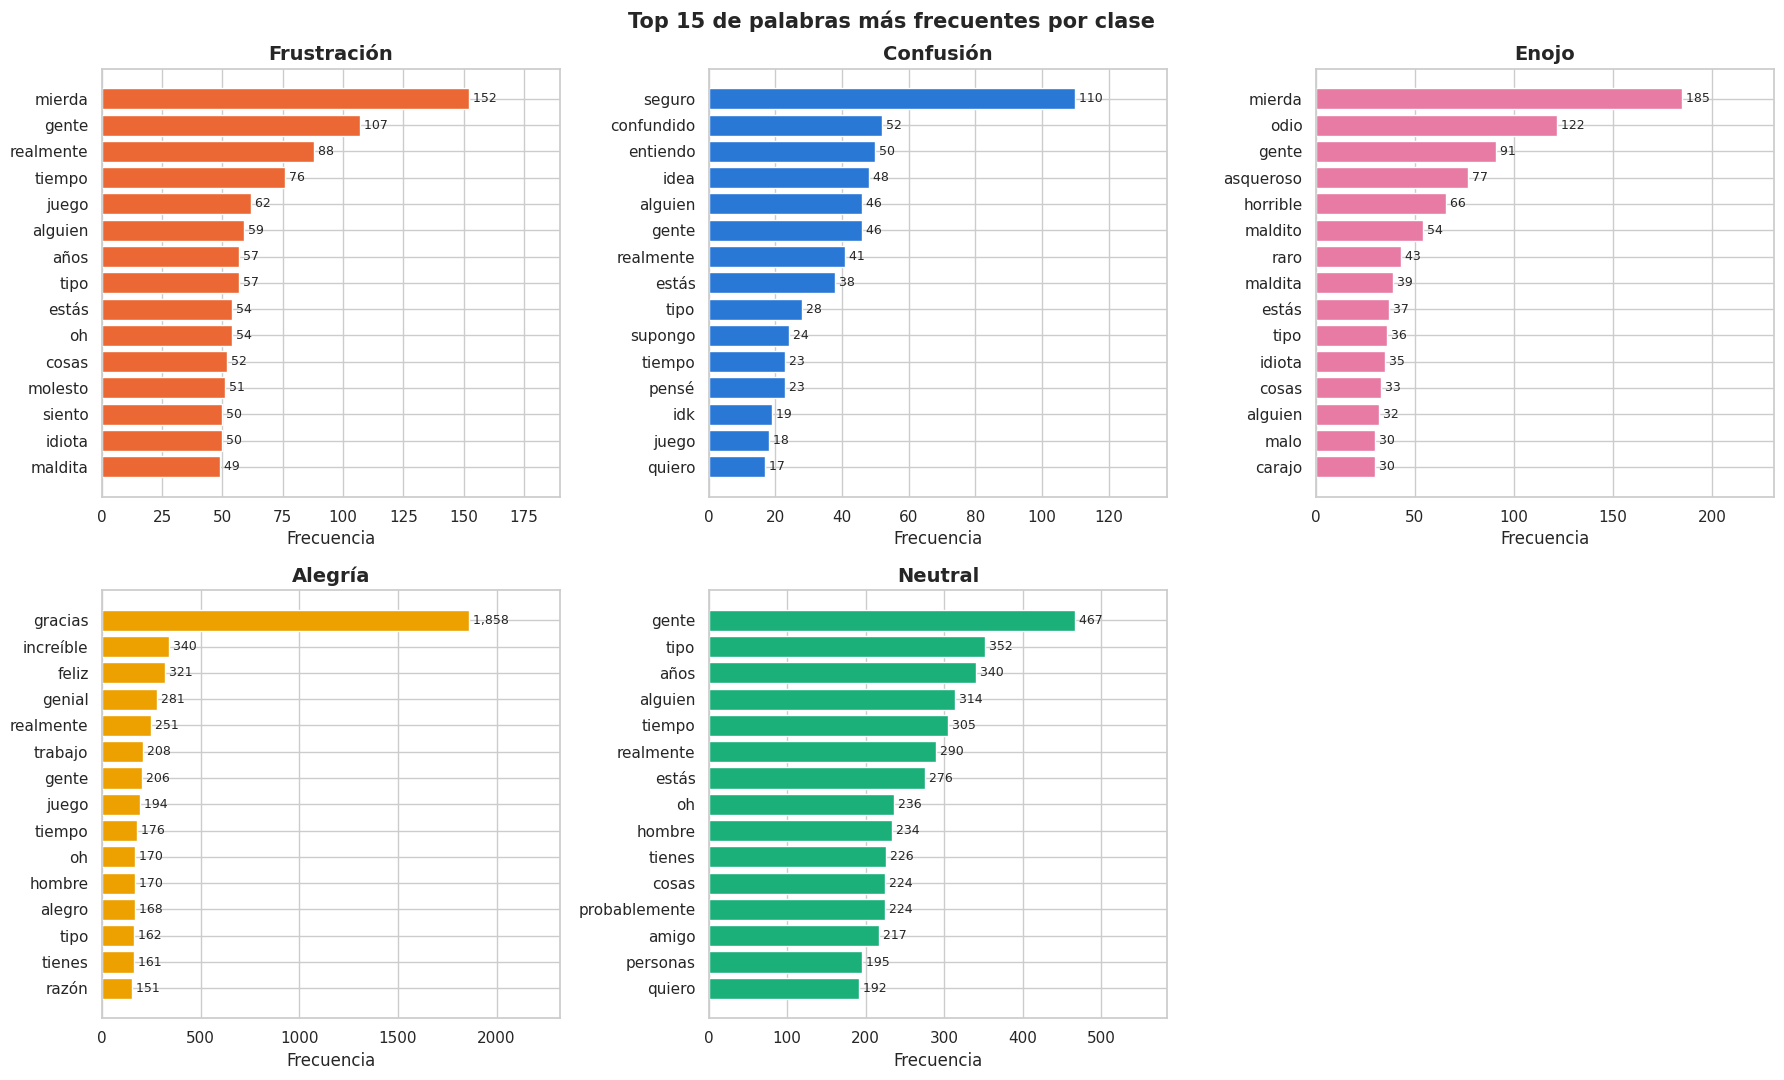

In [43]:
TOP_PALABRAS = 15

def graficar_top_por_clase(top_por_clase, titulo, etiqueta_x, formato="{:,.0f}"):
    fig, ejes = plt.subplots(2, 3, figsize=(18, 11))
    ejes = ejes.flatten()
    for ax, clase in zip(ejes, ORDEN_CLASES):
        datos = top_por_clase[clase].sort_values()
        ax.barh(datos.index, datos.values, color=PALETA_CLASES[clase])
        for i, valor in enumerate(datos.values):
            ax.text(valor, i, " " + formato.format(valor), va="center", fontsize=9)
        ax.set_xlim(0, datos.max() * 1.25)
        ax.set_title(NOMBRES_CLASES[clase])
        ax.set_xlabel(etiqueta_x)
    ejes[-1].axis("off")
    fig.suptitle(titulo, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

top_frecuencia = {
    clase: pd.Series(Counter(
        palabra for tokens in df_vocabulario.loc[df_vocabulario["clase"] == clase, "tokens"] for palabra in tokens
    )).nlargest(TOP_PALABRAS)
    for clase in ORDEN_CLASES
}
graficar_top_por_clase(top_frecuencia, f"Top {TOP_PALABRAS} de palabras más frecuentes por clase", "Frecuencia")

#### 2.8.2 Palabras características por clase según TF-IDF promedio

La frecuencia cruda favorece las palabras comunes a todas las clases (por ejemplo, "si" o "gente" pueden aparecer arriba en varias). El **TF-IDF** reduce el peso de las palabras que aparecen en muchos textos, así que el promedio del TF-IDF de cada palabra dentro de una clase destaca mejor el vocabulario propio de esa clase. Se consideran solo palabras que aparecen en al menos 5 textos, para evitar que palabras rarísimas dominen el ranking.

Tamaño del vocabulario (palabras en al menos 5 textos): 5,250


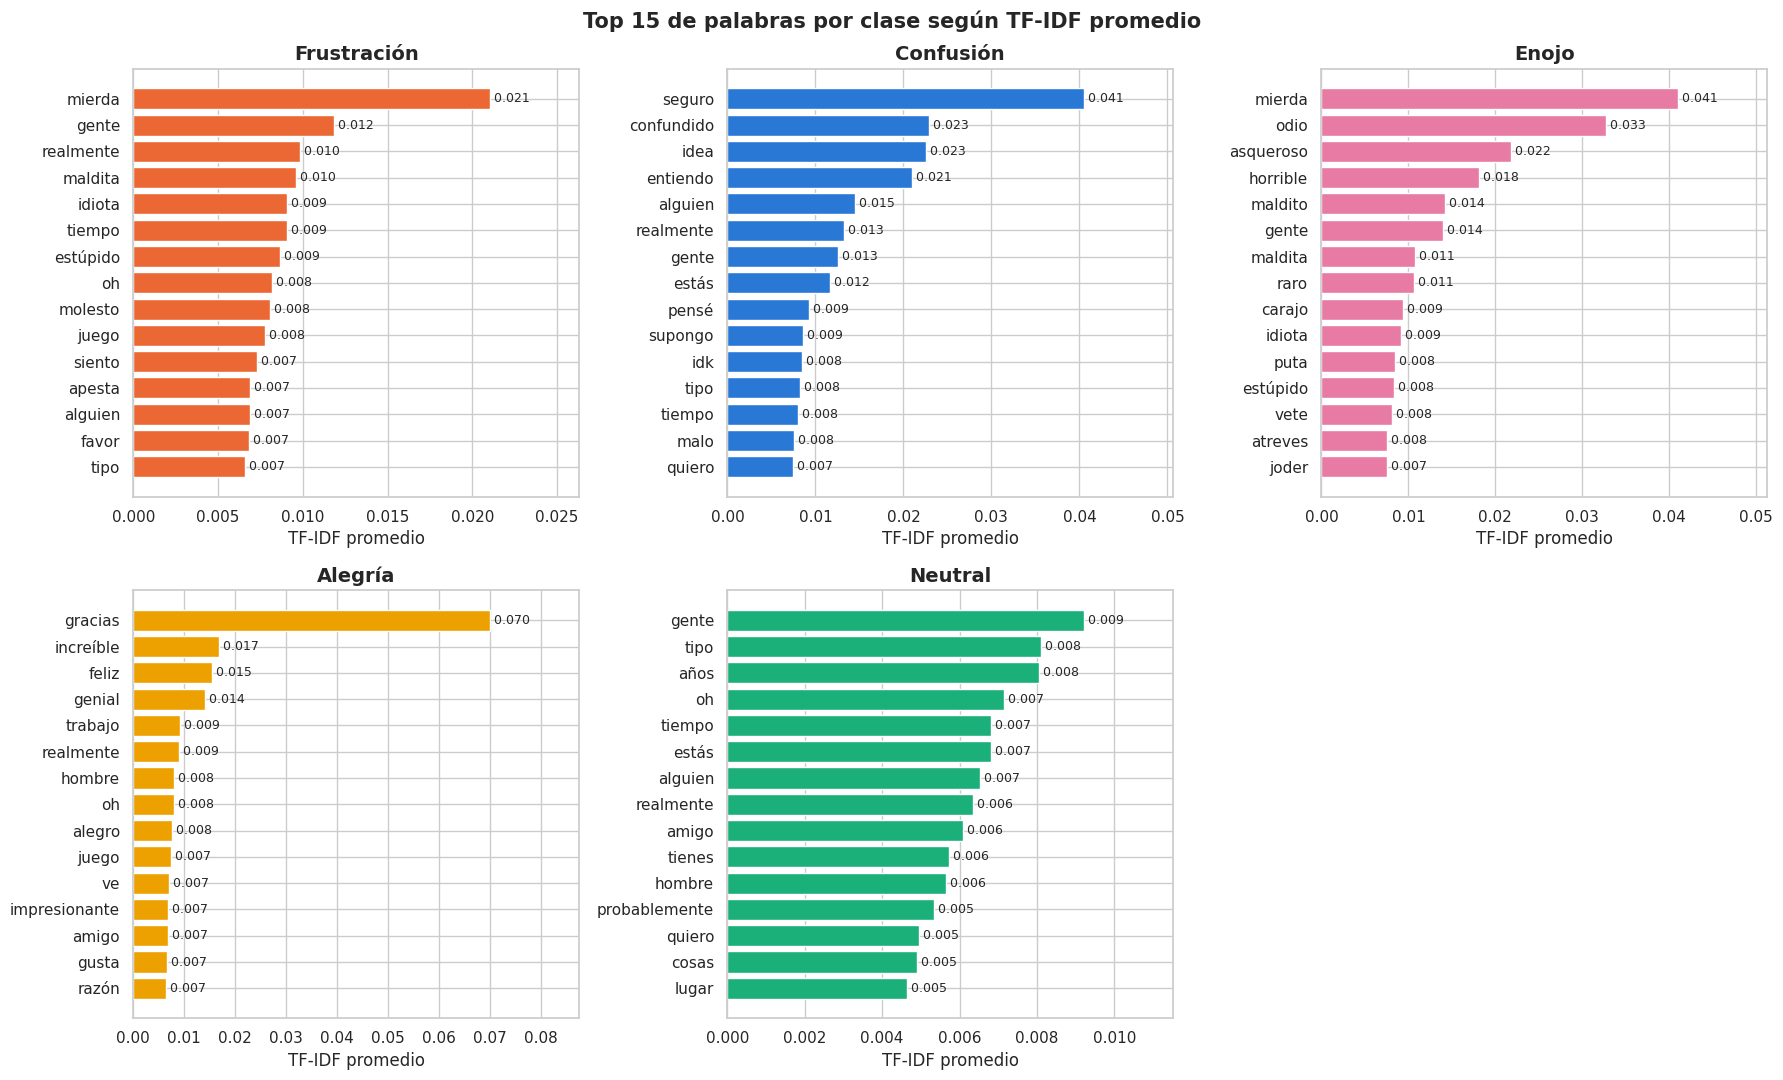

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizador = TfidfVectorizer(min_df=5)
matriz_tfidf = vectorizador.fit_transform(df_vocabulario["texto_normalizado"])
vocabulario = vectorizador.get_feature_names_out()

top_tfidf = {}
for clase in ORDEN_CLASES:
    filas_clase = (df_vocabulario["clase"] == clase).to_numpy()
    promedio = np.asarray(matriz_tfidf[filas_clase].mean(axis=0)).ravel()
    top_tfidf[clase] = pd.Series(promedio, index=vocabulario).nlargest(TOP_PALABRAS)

print(f"Tamaño del vocabulario (palabras en al menos 5 textos): {len(vocabulario):,}")
graficar_top_por_clase(top_tfidf, f"Top {TOP_PALABRAS} de palabras por clase según TF-IDF promedio",
                       "TF-IDF promedio", formato="{:.3f}")

#### 2.8.3 Nubes de palabras por clase

Las nubes de palabras resumen visualmente el vocabulario de cada clase: el tamaño de cada palabra es proporcional a su frecuencia. Cada nube usa el color de su clase.

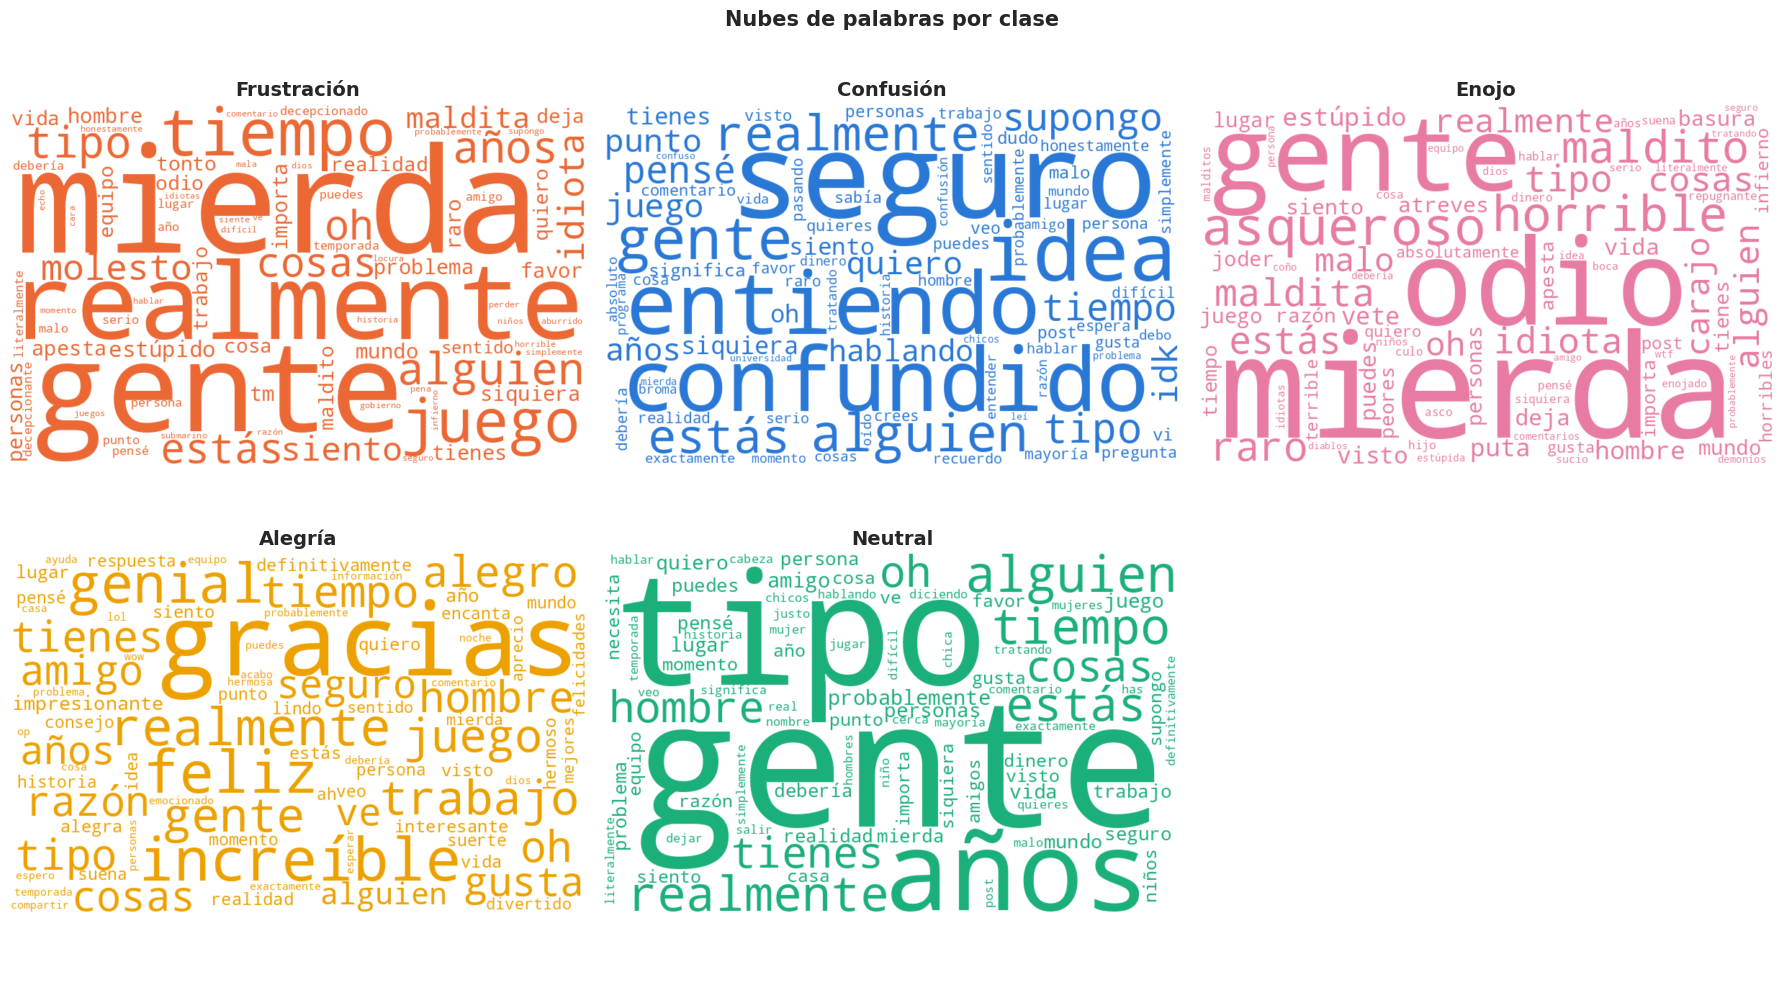

In [45]:
from wordcloud import WordCloud

fig, ejes = plt.subplots(2, 3, figsize=(18, 10))
ejes = ejes.flatten()
for ax, clase in zip(ejes, ORDEN_CLASES):
    frecuencias = Counter(
        palabra for tokens in df_vocabulario.loc[df_vocabulario["clase"] == clase, "tokens"] for palabra in tokens
    )
    nube = WordCloud(width=800, height=500, background_color="white", max_words=80,
                     color_func=lambda *args, color=PALETA_CLASES[clase], **kwargs: color,
                     random_state=SEMILLA).generate_from_frequencies(frecuencias)
    ax.imshow(nube, interpolation="bilinear")
    ax.set_title(NOMBRES_CLASES[clase])
    ax.axis("off")
ejes[-1].axis("off")
fig.suptitle("Nubes de palabras por clase", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: comentar si el vocabulario de cada clase tiene sentido. Por ejemplo, si "gracias" aparece en alegría, si en confusión aparecen expresiones como "entiendo", "qué" o "seguro", y si en enojo aparecen insultos o groserías. Señalar las palabras que delatan un dominio no educativo, como nombres de equipos, términos de fútbol, política o videojuegos ([COMPLETAR: palabras concretas observadas]). Esto confirma que los datos provienen de Reddit y no de mensajes de estudiantes, lo que justifica complementarlos con datos de contexto educativo (subsección 2.11).]

**Cifras clave de 2.8**

- Tamaño del vocabulario usado en el análisis TF-IDF: [COMPLETAR] palabras.

### 2.9 Calidad de la traducción y ejemplos por clase

Como los textos se tradujeron automáticamente, se revisan ejemplos concretos para evaluar de forma cualitativa la calidad de los datos.

#### 2.9.1 Ejemplos aleatorios por clase

Se muestran 5 ejemplos aleatorios por clase, con el texto original en inglés junto a su traducción y la emoción original.

In [46]:
for clase in ORDEN_CLASES:
    print(f"\n=== {NOMBRES_CLASES[clase]} ===")
    display(
        df_limpio[df_limpio["clase"] == clase]
        .sample(5, random_state=SEMILLA)[["text", "text_es", "emocion_original"]]
        .reset_index(drop=True)
    )


=== Frustración ===


,text,text_es,emocion_original
0,are you dumb bro? please watch again and don’t downvote me for stating facts. holy shit you’re inept.,"¿Eres un hermano tonto? Por favor, mira de nuevo y no me rechaces por declarar hechos. Dios santo, eres inepto.",annoyance
1,It’s 2019 dude chill out with the gender roles Edit: it’s 2019 I’m tired sorry,Es 2019 amigo relajarse con los roles de género Editar: es 2019 Estoy cansado lo siento,disappointment
2,He said he says it on his own but I don't want him to say it at all. I feel like their bio mom hates me,"Dijo que lo dice por su cuenta, pero no quiero que lo diga en absoluto. Siento que su madre biológica me odia.",annoyance
3,"It an argument. Don’t really have time for jack-assery. Lot of people want attention from me tonight, not just you.","Es una discusión. Realmente no tiene tiempo para jack-assery. Mucha gente quiere atención de mí esta noche, no sólo tú.",annoyance
4,Dumpster fire. I cant quit you Edmonton!!,Fuego en el contenedor. ¡No puedo dejarte Edmonton!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,annoyance



=== Confusión ===


,text,text_es,emocion_original
0,Isn't that why [NAME] is playing him?,¿No es por eso que [NOMBRE] está jugando con él?,confusion
1,As QA I can confirm that I have no idea what I'm doing,Como QA puedo confirmar que no tengo ni idea de lo que estoy haciendo,confusion
2,Every BP within cooeee of me is consistently 5-10 cents a liter higher than other options. Weird.,Cada presión arterial dentro de mí es consistentemente 5-10 centavos por litro más alto que otras opciones. Raro.,confusion
3,Rainy weather must have gotten them... no idea. But i've never seen a dead hummingbird and saw 2 within 5 feet of each other :(,El clima lluvioso debe haberlos conseguido... ni idea. Pero nunca he visto un colibrí muerto y vi 2 a menos de 5 pies el uno del otro :(,confusion
4,Idk if I want [NAME] back but I agree with [NAME] ONLY if he keeps playing at this level by the end of he season.,Idk si quiero recuperar [NOMBRE] pero estoy de acuerdo con [NOMBRE] SOLO si sigue jugando a este nivel al final de la temporada.,confusion



=== Enojo ===


,text,text_es,emocion_original
0,PayPal is fucking pricey. 500 bucks to Mexico cost me 60$,PayPal es caro. 500 dólares a México me costaron 60 dólares,anger
1,"Weird! Also in Winnipeg, no issues. Do you have a VPN?","¡Raro! También en Winnipeg, no hay problemas. ¿Tienes una VPN?",disgust
2,I HAVE BEEN CALLED! I MUST ANSWER....ALWAAAAAAAYYYYYSSSSSS! *Death Scream*,¡Me han llamado! Tengo que responder... ¡aaaaaaaaaaaaaaaaaaaaaaaa! *Grito de muerte*,anger
3,"If someone has tithed 10% their entire life, fuck off with requests like this.","Si alguien ha diezmado el 10% toda su vida, vete a la mierda con peticiones como esta.",anger
4,"""Get the fuck out of the fucking chair"", or something to that avail.","""Sal de la puta silla"", o algo en ese sentido.",anger



=== Alegría ===


,text,text_es,emocion_original
0,Yes sir ! Cheers. I miss typed I get #120 20mg.,"¡Sí, señor! Salud. Echo de menos el mecanografiado. Obtengo #120 20mg.",approval
1,Happy cake day mothafucka,Feliz día del pastel mothafucka,joy
2,You clearly know exactly what your talking about with your medical terminology...damn your intelligent. 🖕,Claramente sabes exactamente de qué estás hablando con tu terminología médica... maldita sea tu inteligente. * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *,admiration
3,"This artwork is amazing! Only thing that bothers me a bit, is that [NAME] is wearing something that looks like Korean traditional wear as opposed to a kimono","¡Esta obra de arte es increíble! Lo único que me molesta un poco, es que [NOMBRE] está usando algo que se parece a la ropa tradicional coreana en lugar de un kimono",admiration
4,"Now I'm imagining him responding to your dirty talk with an enthusiastic ""yummy!""","Ahora me lo imagino respondiendo a tu sucia charla con un entusiasta ""delicioso"".",excitement



=== Neutral ===


,text,text_es,emocion_original
0,Braves clubhouse report podcast says don't write off [NAME] to the Braves. Podcast removed from my subscription list. Lol,El podcast de Braves Clubhouse dice que no descartes [NOMBRE] a los Braves. Podcast eliminado de mi lista de suscripción. Lol,neutral
1,Driving drunk and killing people is where it stops,Conducir borracho y matar gente es donde se detiene,neutral
2,That sounds delicious! Looks like I’m making a trip to the supermarket today.,¡Eso suena delicioso! Parece que estoy haciendo un viaje al supermercado hoy.,neutral
3,"Also, this clip seems to be as deceptively-edited as the one [NAME] put forward at the beginning of this entire mess.","Además, este clip parece ser tan engañosamente editado como el que [NOMBRE] presentó al principio de todo este lío.",neutral
4,"If you're on a budget, anywhere that's cheap.","Si tienes un presupuesto, en cualquier parte eso es barato.",neutral


#### 2.9.2 Ejemplos de fallos de la traducción automática

La traducción automática falla sobre todo con la jerga, las groserías y las expresiones idiomáticas. Por ejemplo, en la exploración inicial apareció "if he does off himself" ("si se suicida") traducido como "si lo hace fuera de sí mismo", que cambia por completo el sentido. Ese ejemplo tiene la etiqueta `neutral`, así que se busca en `df_crudo`:

In [47]:
df_crudo[df_crudo["text"].str.contains("does off himself", case=False, regex=False)][["text", "text_es", "labels"]]

,text,text_es,labels
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead","Ahora, si lo hace fuera de sí mismo, todo el mundo pensará que está teniendo una risa jodiendo con la gente en lugar de realmente muerto",[27]


Para encontrar más casos de forma sistemática se usan dos indicadores:

- **Proporción de palabras que quedaron en inglés**: palabras de la traducción que aparecen idénticas en el texto original (sin contar marcadores, números ni palabras de menos de 4 letras, que pueden coincidir por casualidad en ambos idiomas). Una proporción alta indica que el traductor no supo traducir el texto, algo típico con jerga.
- **Proporción de letras en mayúsculas**: los textos escritos en mayúsculas (gritos) suelen traducirse peor.

In [48]:
def proporcion_sin_traducir(fila):
    palabras_es = re.findall(r"[^\W\d_]{4,}", re.sub(PATRON_MARCADOR, " ", fila["text_es"]).lower())
    palabras_en = set(re.findall(r"[^\W\d_]{4,}", fila["text"].lower()))
    if not palabras_es:
        return 0.0
    return sum(palabra in palabras_en for palabra in palabras_es) / len(palabras_es)

def proporcion_mayusculas(texto):
    letras = [c for c in re.sub(PATRON_MARCADOR, " ", texto) if c.isalpha()]
    return sum(c.isupper() for c in letras) / len(letras) if letras else 0.0

df_traduccion = df_limpio[["text", "text_es", "clase", "emocion_original"]].copy()
df_traduccion["prop_sin_traducir"] = df_traduccion.apply(proporcion_sin_traducir, axis=1)
df_traduccion["prop_mayusculas"] = df_traduccion["text_es"].apply(proporcion_mayusculas)

print(f"Textos con al menos un 30 % de palabras sin traducir: {(df_traduccion['prop_sin_traducir'] >= 0.3).sum():,}")
print("\nTextos con mayor proporción de palabras sin traducir:")
display(df_traduccion.sort_values("prop_sin_traducir", ascending=False)
        .head(8)[["text", "text_es", "emocion_original", "prop_sin_traducir"]].round(2))

print("Textos escritos mayoritariamente en mayúsculas:")
display(df_traduccion[df_traduccion["prop_mayusculas"] > 0.8]
        .sample(min(8, (df_traduccion["prop_mayusculas"] > 0.8).sum()), random_state=SEMILLA)
        [["text", "text_es", "emocion_original"]])

Textos con al menos un 30 % de palabras sin traducir: 1,702

Textos con mayor proporción de palabras sin traducir:


,text,text_es,emocion_original,prop_sin_traducir
14355,Rouge Park is federal.,Rouge Park es federal.,neutral,1.0
14395,Stafford Starford Starlord OMG!!!,Stafford Starlord OMG!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,excitement,1.0
12013,He’s from Long Island,Es de Long Island.,neutral,1.0
17836,oh that's sexy,"Oh, eso es sexy.",neutral,1.0
11791,Grace and frankie,Grace y Frankie,neutral,1.0
29126,Soooo [NAME] is f**ked,Soooo [NOMBRE] es f**ked,anger,1.0
28943,Miami - Dade,Miami - Dade,neutral,1.0
10819,What about Dallas and Austin?,¿Qué hay de Dallas y Austin?,neutral,1.0


Textos escritos mayoritariamente en mayúsculas:


,text,text_es,emocion_original
4775,"YEAH, YOU MOTHERFUCKER","SÍ, TU MOTHERFUCKER",anger
26631,DOES NOT COMPUTE WITH MANAGEMENT ALGORITHM,NO COMPUTA CON ALGORITMO DE GESTIÓN,neutral
19336,SHAVE YOUR BEAR,APOYA TU HERMANO,neutral
13370,I HEAVILY VIBE WITH THIS,ESTOY VIBIENDO CON ESTO.,joy
9468,SAMMY HAGAR DR 0-0-0-0-0-10-0-0-01-0-01-0-0-10-0-0 HELL YEAH BROTHER SAMMY HAGAR *SAMMY HAGAR* SAMMY SAMMY HAGAR HAGAR,SAMMY HAGAR DR 0-0-0-0-10-0-0-01-0-01-0-0-10-0-0-0 INFIERNO SÍ HERMANO SAMMY HAGAR *Sammy HAGAR* Sammy SAMMY HAGAR HAGAR,neutral
22351,[NAME] ROASTING LIBERAL CUCKS COMPILATION #43,[NOMBRE] RECOPILACIÓN DE CUCKES LIBERALES #43,neutral
18583,AND KEEP ACKBAR,Y MANTENGA ACKBAR,neutral
29885,YOU MUST CONSTRUCT ADDITIONAL PYLONS,DEBERÍA CONSTRUCTAR PILONES ADICIONALES,neutral


**Interpretación.** [COMPLETAR tras ejecutar: describir los tipos de error observados en los ejemplos (jerga sin traducir, groserías traducidas de forma literal o suavizada, expresiones idiomáticas traducidas palabra por palabra) y su frecuencia aproximada: [COMPLETAR] textos tienen al menos un 30 % de palabras sin traducir.]

**Limitaciones del dataset**

1. **Dominio distinto al del proyecto.** Los textos son comentarios de Reddit sobre temas muy variados (deportes, política, videojuegos, relaciones personales), no mensajes de estudiantes a un tutor.
2. **Traducción automática con errores**, sobre todo en jerga, groserías y expresiones idiomáticas, como muestran los ejemplos anteriores.
3. **Las etiquetas se asignaron sobre el texto en inglés.** Si la traducción cambia el sentido o el tono de un comentario, su etiqueta puede dejar de corresponder a la emoción que se percibe en español.
4. **La frontera entre frustración y enojo es difusa.** `annoyance` (frustración) y `anger` (enojo) expresan grados distintos de una misma reacción negativa y aparecen juntas en comentarios multietiqueta, como se vio en 2.3.3.
5. **Desbalance de clases**, analizado en 2.6.

Estas limitaciones motivan dos medidas en el resto del proyecto: **añadir mensajes de contexto educativo** generados con un modelo de lenguaje (subsección 2.11) y evaluar el modelo final con **un conjunto de prueba escrito por personas**.

### 2.10 Decisión de balanceo y construcción del dataset final

**Tope de ejemplos por clase.** Se fija un tope de ejemplos por clase y las clases que lo superan se submuestrean de forma aleatoria; las que están por debajo se conservan completas. El tope se calcula a partir del tamaño de la clase minoritaria, acotado entre 1.000 y 1.500 ejemplos:

$$\text{tope} = \min\big(\max(n_{\text{minoritaria}},\ 1000),\ 1500\big)$$

Así, si la clase minoritaria tiene entre 1.000 y 1.500 ejemplos, el tope coincide con su tamaño y el dataset queda totalmente balanceado; si tiene menos de 1.000, el tope se queda en 1.000 para no desperdiciar demasiados datos de las demás clases; y si tiene más de 1.500, el tope se limita a 1.500 para contener el costo computacional.

**Submuestreo estratificado.** Dentro de cada clase que se submuestrea, la muestra se estratifica por emoción original, de modo que se mantiene la composición interna de la clase observada en 2.4.3 (por ejemplo, la proporción entre `annoyance` y `disappointment` en frustración). Se usa la semilla fija para que el resultado sea reproducible.

**Justificación**

- **Por qué se submuestrea.** Reduce el desbalance entre clases y el costo computacional: la evaluación se hará con un *repeated k-fold* de 10 × 10 (100 entrenamientos por modelo), y entrenar con todas las filas de `neutral` y `alegria` multiplicaría el tiempo sin aportar información proporcional.
- **Por qué no se sobremuestrea.** Duplicar ejemplos de las clases minoritarias no aporta información nueva y favorece el sobreajuste; además, durante la validación cruzada un mismo texto duplicado podría quedar a la vez en entrenamiento y en validación, lo que inflaría las métricas. SMOTE no tiene sentido directo sobre texto, porque interpola entre vectores numéricos; podría aplicarse sobre los embeddings, pero tendría que hacerse dentro del *pipeline* de cada partición de la validación cruzada para no generar *data leakage*, así que no se aplica en esta etapa.
- **El desbalance que quede** se manejará con `class_weight="balanced"` en los clasificadores.

In [49]:
from sklearn.model_selection import train_test_split

conteo_antes = df_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
n_minoritaria = conteo_antes.min()
TOPE_POR_CLASE = int(min(max(n_minoritaria, 1000), 1500))
print(f"Clase minoritaria: {conteo_antes.idxmin()} con {n_minoritaria:,} ejemplos")
print(f"Tope por clase: {TOPE_POR_CLASE:,}")

partes = []
for clase in ORDEN_CLASES:
    df_clase = df_limpio[df_limpio["clase"] == clase]
    if len(df_clase) > TOPE_POR_CLASE:
        # Submuestreo aleatorio estratificado por emoción original
        df_clase, _ = train_test_split(
            df_clase, train_size=TOPE_POR_CLASE,
            stratify=df_clase["emocion_original"], random_state=SEMILLA,
        )
    partes.append(df_clase)
df_balanceado = pd.concat(partes).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)

conteo_despues = df_balanceado["clase"].value_counts().reindex(ORDEN_CLASES)
display(pd.DataFrame({"antes": conteo_antes, "después": conteo_despues}).rename_axis("clase"))
print(f"Total antes: {conteo_antes.sum():,} | total después: {conteo_despues.sum():,}")
print(f"Ratio de desbalance después: {conteo_despues.max() / conteo_despues.min():.2f}")

Clase minoritaria: confusion con 1,036 ejemplos
Tope por clase: 1,036


,antes,después
clase,,
frustracion,2654,1036
confusion,1036,1036
enojo,1785,1036
alegria,9319,1036
neutral,15382,1036


Total antes: 30,176 | total después: 5,180
Ratio de desbalance después: 1.00


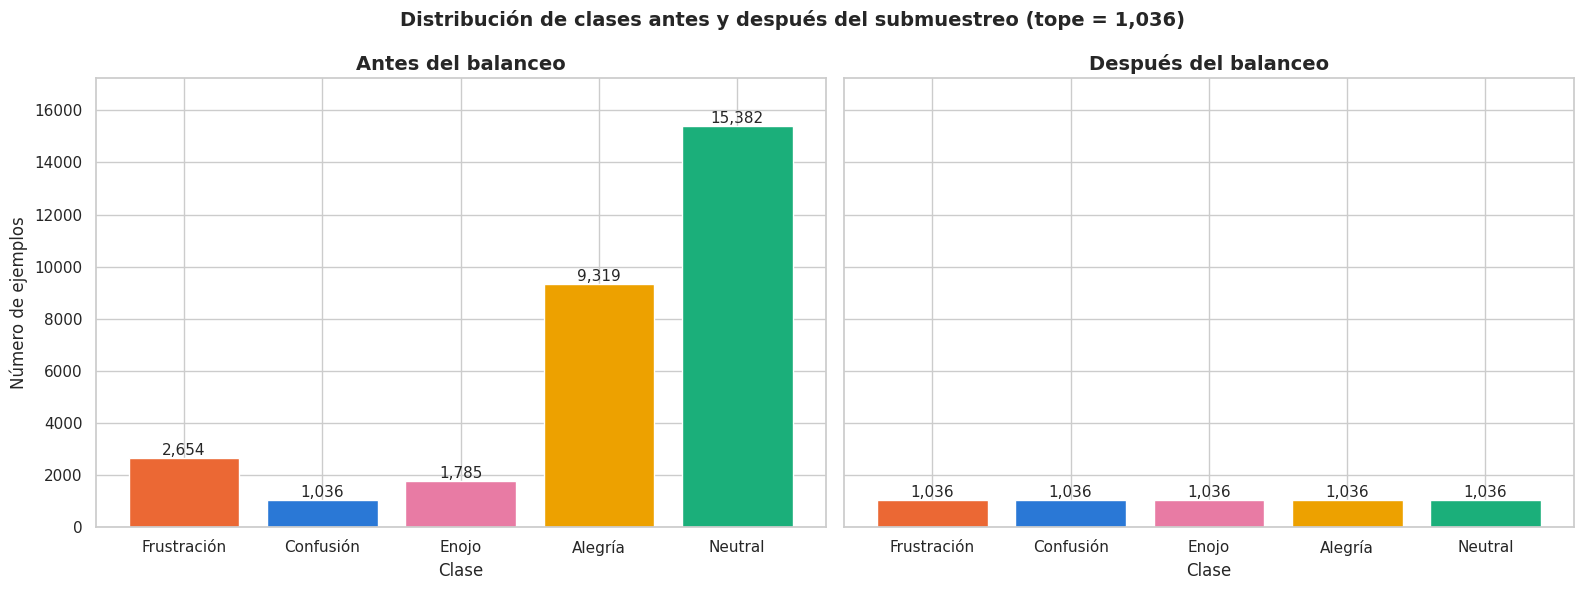

In [50]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
nombres = [NOMBRES_CLASES[c] for c in ORDEN_CLASES]
colores = [PALETA_CLASES[c] for c in ORDEN_CLASES]
for ax, conteo, titulo in zip(ejes, [conteo_antes, conteo_despues], ["Antes del balanceo", "Después del balanceo"]):
    barras = ax.bar(nombres, conteo.values, color=colores)
    for barra, n in zip(barras, conteo.values):
        ax.annotate(f"{n:,}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    ha="center", va="bottom", fontsize=11)
    ax.set_title(titulo)
    ax.set_xlabel("Clase")
ejes[0].set_ylabel("Número de ejemplos")
ejes[0].set_ylim(0, conteo_antes.max() * 1.12)
fig.suptitle(f"Distribución de clases antes y después del submuestreo (tope = {TOPE_POR_CLASE:,})",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Dataset final.** Se conservan las columnas mínimas: el texto en español (renombrado a `texto`), la clase, la emoción original y una columna `fuente` con el valor `goemotions`. Esta última columna queda preparada para cuando se agreguen los mensajes educativos generados con un modelo de lenguaje, que tendrán `fuente = sintetico`. El dataset se guarda en `data/dataset_final.csv` para no repetir todo el procesamiento en las secciones siguientes.

In [51]:
df_final = (
    df_balanceado[["text_es", "clase", "emocion_original"]]
    .rename(columns={"text_es": "texto"})
    .assign(fuente="goemotions")
    .reset_index(drop=True)
)

os.makedirs("data", exist_ok=True)
RUTA_DATASET_FINAL = os.path.join("data", "dataset_final.csv")
df_final.to_csv(RUTA_DATASET_FINAL, index=False)

print(f"Dataset final guardado en {RUTA_DATASET_FINAL}: {df_final.shape[0]:,} filas, {df_final.shape[1]} columnas")
df_final.head()

Dataset final guardado en data/dataset_final.csv: 5,180 filas, 4 columnas


,texto,clase,emocion_original,fuente
0,La última vez que supe que robar postes de otras personas no era una regla.,frustracion,annoyance,goemotions
1,"¿Podría explicarlo, por favor? Entiendo cada palabra, pero no la frase.",confusion,confusion,goemotions
2,"No recuerdo, todo estaba muy borroso...",frustracion,disappointment,goemotions
3,Esto. Y el Dr. [NOMBRE] le dijo que probablemente era la persona más pesada del mundo en ese momento.,neutral,neutral,goemotions
4,un comercio interesante sería [NOMBRE] y un primero a los Mavs para [NOMBRE]. y [NOMBRE],neutral,neutral,goemotions


**Interpretación.** [COMPLETAR tras ejecutar: el tope quedó en [COMPLETAR] ejemplos por clase. Se submuestrearon las clases [COMPLETAR], y [COMPLETAR] se conservaron completas. El ratio de desbalance pasó de [COMPLETAR] a [COMPLETAR].]

**Cifras clave de 2.10**

- Filas antes del balanceo: [COMPLETAR] → filas del dataset final: [COMPLETAR].
- Ejemplos por clase en el dataset final: frustración = [COMPLETAR], confusión = [COMPLETAR], enojo = [COMPLETAR], alegría = [COMPLETAR], neutral = [COMPLETAR].

### 2.11 Integración de los datos sintéticos educativos

*Subsección pendiente: se completará cuando se generen los mensajes.*

Para reducir la diferencia de dominio entre Reddit y los mensajes de estudiantes, se agregarán mensajes de contexto educativo generados con un modelo de lenguaje. Cuando estén disponibles, en esta subsección se deberá:

1. Cargar los mensajes generados y mostrar su distribución por clase.
2. Incluir, como comentario en el código o en una celda Markdown, el prompt usado para generarlos.
3. Eliminar duplicados y casi duplicados.
4. Comparar la longitud y el vocabulario de GoEmotions con los de los datos sintéticos.
5. Concatenarlos al dataset final, identificándolos con `fuente = sintetico`.

### 2.12 Conclusiones del EDA

[COMPLETAR tras ejecutar la notebook completa, con las cifras obtenidas:]

1. **Tamaño del dataset final.** De los [COMPLETAR] comentarios originales se conservan [COMPLETAR] tras filtrar los de una sola etiqueta, agrupar en las cinco clases, limpiar y balancear. El dataset final tiene [COMPLETAR] ejemplos: frustración = [COMPLETAR], confusión = [COMPLETAR], enojo = [COMPLETAR], alegría = [COMPLETAR], neutral = [COMPLETAR].
2. **Desbalance.** Tras la limpieza, el ratio de desbalance era de [COMPLETAR] (`[COMPLETAR]` frente a `[COMPLETAR]`). Por eso se evaluará con **F1-macro** y no con exactitud. El submuestreo con tope de [COMPLETAR] lo redujo a [COMPLETAR], y el desbalance restante se compensará con `class_weight="balanced"`.
3. **Longitud y vocabulario.** Los textos son cortos (mediana de [COMPLETAR] palabras, percentil 95 de [COMPLETAR]), así que la truncación del encoder no será un problema. [COMPLETAR: si la longitud distingue o no las clases.] El vocabulario es coherente con las clases ([COMPLETAR: ejemplos]), pero contiene términos de dominios ajenos a la educación ([COMPLETAR: ejemplos]).
4. **Clases difíciles de separar.** [COMPLETAR: se anticipa que frustración y enojo serán las clases más difíciles de separar, porque `annoyance` y `anger` aparecen juntas en [COMPLETAR] comentarios multietiqueta y comparten vocabulario negativo; también confusión frente a neutral, si las preguntas neutras se parecen a las de confusión.] Esto se volverá a revisar en la visualización t-SNE y en la matriz de confusión.
5. **Limitaciones y mitigación.** El dominio de Reddit, los errores de traducción automática y las etiquetas asignadas sobre el texto en inglés limitan la validez de los datos para el tutor. Se mitigan añadiendo mensajes de contexto educativo (subsección 2.11) y evaluando el modelo final con un conjunto de prueba escrito por personas.